In [1]:
import logging

import numpy as np
import optimistix as optx
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec

from atmodeller import (
    InteriorAtmosphere,
    Planet,
    SolverParameters,
    Species,
    SpeciesCollection,
    debug_logger,
)
from atmodeller.eos import get_eos_models
from atmodeller.solubility import get_solubility_models
from atmodeller.thermodata import IronWustiteBuffer

import plotly.graph_objects as go
from plotly.subplots import make_subplots
import plotly.io as pio
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import gridspec
from scipy.signal import savgol_filter


logger = debug_logger()
logger.setLevel(logging.INFO)
# For more output use DEBUG
# logger.setLevel(logging.DEBUG)

Atmodeller initialized with double precision (float64)


# Sub-Neptune (e.g. K2-18b) models from Bower et al. (2025)

The code blocks below must always be run, but then you can preferentially run only the models for ideal or real gases.

Parameters for the simulations

In [2]:
eos_models = get_eos_models()
sol_models = get_solubility_models()

# Gases 
H2O_gs = Species.create_gas(
    "H2O", 
    solubility=sol_models["H2O_peridotite_sossi23"]
    )
H2O_rgs = Species.create_gas(
    "H2O", 
    activity=eos_models["H2O_cork_holland98"],
    solubility=sol_models["H2O_peridotite_sossi23"]
    )

H2_gs = Species.create_gas(
    "H2", 
    solubility=sol_models["H2_basalt_hirschmann12"]
    )
H2_rgs = Species.create_gas(
    "H2", 
    activity=eos_models["H2_chabrier21"], 
    solubility=sol_models["H2_basalt_hirschmann12"]
    )

O2_g = Species.create_gas(
    "O2"
    )
O2_rg = Species.create_gas(
    "O2", 
    activity=eos_models["O2_cs_shi92"]
    )


CO2_gs = Species.create_gas(
    "CO2", solubility=sol_models["CO2_basalt_dixon95"]
)

CO2_rgs = Species.create_gas(
    "CO2", solubility=sol_models["CO2_basalt_dixon95"], activity=eos_models["CO2_cs_shi92"]
)

CO_gs = Species.create_gas(
    "CO", solubility=sol_models["CO_basalt_yoshioka19"]
)
CO_rgs = Species.create_gas(
    "CO", solubility=sol_models["CO_basalt_yoshioka19"], activity=eos_models["CO_cs_shi92"]
)

CH4_gs = Species.create_gas(
    "CH4", solubility=sol_models["CH4_basalt_ardia13"]
)
CH4_rgs = Species.create_gas(
    "CH4", solubility=sol_models["CH4_basalt_ardia13"], activity=eos_models["CH4_cs_shi92"]
)

N2_gs = Species.create_gas(
    "N2", solubility=sol_models["N2_basalt_libourel03"]
)
N2_rgs = Species.create_gas(
    "N2", solubility=sol_models["N2_basalt_libourel03"], activity=eos_models["N2_cs_saxena87"]
)

NH3_g = Species.create_gas("H3N")
NH3_rg = Species.create_gas("H3N", activity=eos_models["H3N_rk49_reid87"])


CHN_g = Species.create_gas("CHN")
CHN_rg = Species.create_gas("CHN", activity=eos_models["CHN_rk49_reid87"])

He_gs = Species.create_gas(
    "He", solubility=sol_models["He_basalt_jambon86"]
)
He_rgs = Species.create_gas(
    "He", solubility=sol_models["He_basalt_jambon86"], activity=eos_models["He_chabrier21"]
)


species_ideal = SpeciesCollection(
    (
        H2O_gs,
        H2_gs,
        O2_g,
        CO2_gs,
        CO_gs,
        CH4_gs,
        N2_gs,
        NH3_g,
        CHN_g,
        He_gs,
    )
)

species_real = SpeciesCollection(
    (
        H2O_rgs,
        H2_rgs,
        O2_rg,
        CO2_rgs,
        CO_rgs,
        CH4_rgs,
        N2_rgs,
        NH3_rg,
        CHN_rg,
        He_rgs,
    )
)

In [3]:
number_of_realisations = 50

# For simulations with fixed mass and surface radius:
planet_mass = 5.154e25
surface_radius = 1.1225e7  # using M-R relation from Hakim+2018

ALL_VALUES = []

RANDOM_SEED = 0
np.random.seed(RANDOM_SEED)

## Hydrogen fraction

Where does saturation occur

In [13]:
import numpy as np

# ===========================================================
# 1. Lodders (2009) solar composition mass fractions (wt%)
# ===========================================================
H_masspercent_lodders09  = 73.9
He_masspercent_lodders09 = 24.69
C_masspercent_lodders09  = 0.22
N_masspercent_lodders09  = 0.07
O_masspercent_lodders09  = 0.63

# Ratios relative to hydrogen (Solar)
C_H_RATIO_SOLAR  = C_masspercent_lodders09  / H_masspercent_lodders09
N_H_RATIO_SOLAR  = N_masspercent_lodders09  / H_masspercent_lodders09
O_H_RATIO_SOLAR  = O_masspercent_lodders09  / H_masspercent_lodders09
He_H_RATIO_SOLAR = He_masspercent_lodders09 / H_masspercent_lodders09


# ===========================================================
# 2. Function to get metal-enriched budgets
# ===========================================================
def get_enriched_budget(h_kg, metallicity_factor=100):
    """
    Returns C, N, O, and He masses based on solar H ratios,
    with C, N, O enriched by metallicity_factor × solar.
    He stays fixed at the solar He/H ratio.
    """
    return {
        "H":  h_kg,
        "C":  h_kg * C_H_RATIO_SOLAR  * metallicity_factor,
        "N":  h_kg * N_H_RATIO_SOLAR  * metallicity_factor,
        "He": h_kg * He_H_RATIO_SOLAR
    }


# ===========================================================
# 3. Hydrogen mass fraction range: 0.1% → 10% of total planet mass
# ===========================================================
number_of_realisations = 50   # choose as needed

# Hydrogen mass fractions between 0.001 and 0.10
H_mass_fraction = np.logspace(-3, -1, number_of_realisations)
fO2_log10_shifts = np.full(number_of_realisations, -6)

# Convert mass fraction → hydrogen mass in kg
h_kg = H_mass_fraction * planet_mass

mass_constraints = get_enriched_budget(h_kg, metallicity_factor=100)

In [18]:
ELEMENTS = ["H", "C", "N", "He"]

def budget_to_percent_compact(budget):
    """
    Takes the budget dict (arrays) and returns a 2D array:
    rows   = realizations
    cols   = H, C, N, O, He abundances (%)
    """
    # Stack into array shape (5, N)
    arr = np.vstack([budget[key] for key in ELEMENTS])
    
    # Total mass per realization
    total = arr.sum(axis=0)
    
    # Convert to percentages
    percent = (arr / total) * 100.0
    
    return percent.T  # shape (N, 5)


In [19]:
mass_constraints = get_enriched_budget(h_kg, metallicity_factor=100)
percentages = budget_to_percent_compact(mass_constraints)

print(percentages.shape)
print(percentages[:5])   # print only first 5 rows


(50, 4)
[[57.919899678658204 17.242730621522064  5.486323379575202
  19.35104632024453 ]
 [57.91989967865822  17.242730621522064  5.486323379575204
  19.35104632024453 ]
 [57.919899678658204 17.242730621522064  5.486323379575202
  19.35104632024453 ]
 [57.919899678658204 17.24273062152206   5.486323379575202
  19.35104632024453 ]
 [57.919899678658204 17.242730621522064  5.486323379575202
  19.35104632024453 ]]


In [20]:
import pickle
import numpy as np

with open("FILE29.pkl", "rb") as f:
    data = pickle.load(f)

print("Type of data:", type(data))

if isinstance(data, dict):
    print("Dict keys:", list(data.keys()))


Type of data: <class 'dict'>
Dict keys: ['H2O_g', 'H2_g', 'O2_g', 'CO2_g', 'CO_g', 'CH4_g', 'N2_g', 'H3N_g', 'CHN_g', 'He_g', 'element_C', 'element_H', 'element_He', 'element_N', 'element_O', 'planet', 'atmosphere', 'raw', 'constraints', 'residual', 'solver']


In [21]:
import pickle
import numpy as np

# ---- load ----
with open("FILE29.pkl", "rb") as f:
    data = pickle.load(f)

# ---- extract element arrays ----
elements = ["element_H", "element_He", "element_C", "element_N", "element_O"]

# keep only those that exist
elements = [e for e in elements if e in data]

# convert to array stack: shape (n_elements, n_realizations)
arr = np.vstack([np.asarray(data[e]) for e in elements])

# total mass per realisation
total = arr.sum(axis=0)

# compute %
percent = (arr / total) * 100.0

# ---- print summary ----
print("\n=== ELEMENT ABUNDANCES (%): ===")
for i, e in enumerate(elements):
    vals = percent[i]
    print(
        f"{e}: mean={vals.mean():8.4f} %, "
        f"min={vals.min():8.4f} %, "
        f"max={vals.max():8.4f} %"
    )

# ---- check closure ----
sum_percent = percent.sum(axis=0)
print("\nSum of all element % (should be ~100%):")
print(
    f"mean={sum_percent.mean():.6f} %, "
    f"min={sum_percent.min():.6f} %, "
    f"max={sum_percent.max():.6f} %"
)



=== ELEMENT ABUNDANCES (%): ===
element_H: mean=     nan %, min=     nan %, max=     nan %
element_He: mean=     nan %, min=     nan %, max=     nan %
element_C: mean=     nan %, min=     nan %, max=     nan %
element_N: mean=     nan %, min=     nan %, max=     nan %
element_O: mean=     nan %, min=     nan %, max=     nan %

Sum of all element % (should be ~100%):
mean=nan %, min=nan %, max=nan %


/var/folders/l6/yw7hsmzx1czfjt3n32sfq_w00000gn/T/ipykernel_62331/2666790324.py:21: RuntimeWarning: invalid value encountered in divide
  percent = (arr / total) * 100.0


In [6]:
sub_neptune = Planet(
    surface_temperature=3000,
    planet_mass=planet_mass,
    surface_radius=surface_radius,
    mantle_melt_fraction=1,
)

<>:253: SyntaxWarning: invalid escape sequence '\D'
<>:256: SyntaxWarning: invalid escape sequence '\o'
<>:253: SyntaxWarning: invalid escape sequence '\D'
<>:256: SyntaxWarning: invalid escape sequence '\o'
/var/folders/l6/yw7hsmzx1czfjt3n32sfq_w00000gn/T/ipykernel_56136/1025322930.py:253: SyntaxWarning: invalid escape sequence '\D'
  ax.set_title(f"$\Delta$IW = {dIW}")
/var/folders/l6/yw7hsmzx1czfjt3n32sfq_w00000gn/T/ipykernel_56136/1025322930.py:256: SyntaxWarning: invalid escape sequence '\o'
  ax.set_ylabel("Planet Mass [$M_{\oplus}$]")
[14:18:15 - atmodeller.classes             - INFO     ] - species = ('H2O_g: CombinedRealGas, SolubilityPowerLaw', 'H2_g: CombinedRealGas, SolubilityPowerLawLog10', 'O2_g: CombinedRealGas, NoSolubility', 'CO2_g: CombinedRealGas, _CO2_basalt_dixon95', 'CO_g: CombinedRealGas, _CO_basalt_yoshioka19', 'CH4_g: CombinedRealGas, _CH4_basalt_ardia13', 'N2_g: CombinedRealGas, _N2_basalt_libourel03', 'H3N_g: RedlichKwong49, NoSolubility', 'CHN_g: RedlichKwon

Starting simulation loop...
--- Processing dIW = -3 ---


[14:18:51 - atmodeller.classes             - INFO     ] - Solve complete: 1 (100.00%) successful model(s)
[14:18:51 - atmodeller.classes             - INFO     ] - Solver steps (max) = 66
[14:18:51 - atmodeller.output_core         - INFO     ] - Computing to_dataframes output
[14:18:51 - atmodeller.output_core         - INFO     ] - Computing asdict output
[14:18:55 - atmodeller.classes             - INFO     ] - species = ('H2O_g: CombinedRealGas, SolubilityPowerLaw', 'H2_g: CombinedRealGas, SolubilityPowerLawLog10', 'O2_g: CombinedRealGas, NoSolubility', 'CO2_g: CombinedRealGas, _CO2_basalt_dixon95', 'CO_g: CombinedRealGas, _CO_basalt_yoshioka19', 'CH4_g: CombinedRealGas, _CH4_basalt_ardia13', 'N2_g: CombinedRealGas, _N2_basalt_libourel03', 'H3N_g: RedlichKwong49, NoSolubility', 'CHN_g: RedlichKwong49, NoSolubility', 'He_g: CombinedRealGas, SolubilityPowerLaw')
[14:18:55 - atmodeller.classes             - INFO     ] - Thermodynamic data requires temperatures between 200 K and 6000 K


--- Processing dIW = 0 ---


[14:19:24 - atmodeller.classes             - INFO     ] - species = ('H2O_g: CombinedRealGas, SolubilityPowerLaw', 'H2_g: CombinedRealGas, SolubilityPowerLawLog10', 'O2_g: CombinedRealGas, NoSolubility', 'CO2_g: CombinedRealGas, _CO2_basalt_dixon95', 'CO_g: CombinedRealGas, _CO_basalt_yoshioka19', 'CH4_g: CombinedRealGas, _CH4_basalt_ardia13', 'N2_g: CombinedRealGas, _N2_basalt_libourel03', 'H3N_g: RedlichKwong49, NoSolubility', 'CHN_g: RedlichKwong49, NoSolubility', 'He_g: CombinedRealGas, SolubilityPowerLaw')
[14:19:24 - atmodeller.classes             - INFO     ] - Thermodynamic data requires temperatures between 200 K and 6000 K
[14:19:24 - atmodeller.classes             - INFO     ] - reactions = {0: '2.0 H2_g + 2.0 CO_g = 1.0 CO2_g + 1.0 CH4_g',
 1: '1.0 H2_g + 1.0 CO2_g = 1.0 H2O_g + 1.0 CO_g',
 2: '1.5 H2_g + 0.5 N2_g = 1.0 H3N_g',
 3: '0.5 H2_g + 2.0 CO_g + 0.5 N2_g = 1.0 CO2_g + 1.0 CHN_g',
 4: '2.0 CO2_g = 1.0 O2_g + 2.0 CO_g'}
[14:19:24 - atmodeller.classes             - IN

--- Processing dIW = 3 ---


[14:19:54 - atmodeller.classes             - INFO     ] - species = ('H2O_g: CombinedRealGas, SolubilityPowerLaw', 'H2_g: CombinedRealGas, SolubilityPowerLawLog10', 'O2_g: CombinedRealGas, NoSolubility', 'CO2_g: CombinedRealGas, _CO2_basalt_dixon95', 'CO_g: CombinedRealGas, _CO_basalt_yoshioka19', 'CH4_g: CombinedRealGas, _CH4_basalt_ardia13', 'N2_g: CombinedRealGas, _N2_basalt_libourel03', 'H3N_g: RedlichKwong49, NoSolubility', 'CHN_g: RedlichKwong49, NoSolubility', 'He_g: CombinedRealGas, SolubilityPowerLaw')
[14:19:54 - atmodeller.classes             - INFO     ] - Thermodynamic data requires temperatures between 200 K and 6000 K
[14:19:54 - atmodeller.classes             - INFO     ] - reactions = {0: '2.0 H2_g + 2.0 CO_g = 1.0 CO2_g + 1.0 CH4_g',
 1: '1.0 H2_g + 1.0 CO2_g = 1.0 H2O_g + 1.0 CO_g',
 2: '1.5 H2_g + 0.5 N2_g = 1.0 H3N_g',
 3: '0.5 H2_g + 2.0 CO_g + 0.5 N2_g = 1.0 CO2_g + 1.0 CHN_g',
 4: '2.0 CO2_g = 1.0 O2_g + 2.0 CO_g'}
[14:19:54 - atmodeller.classes             - IN

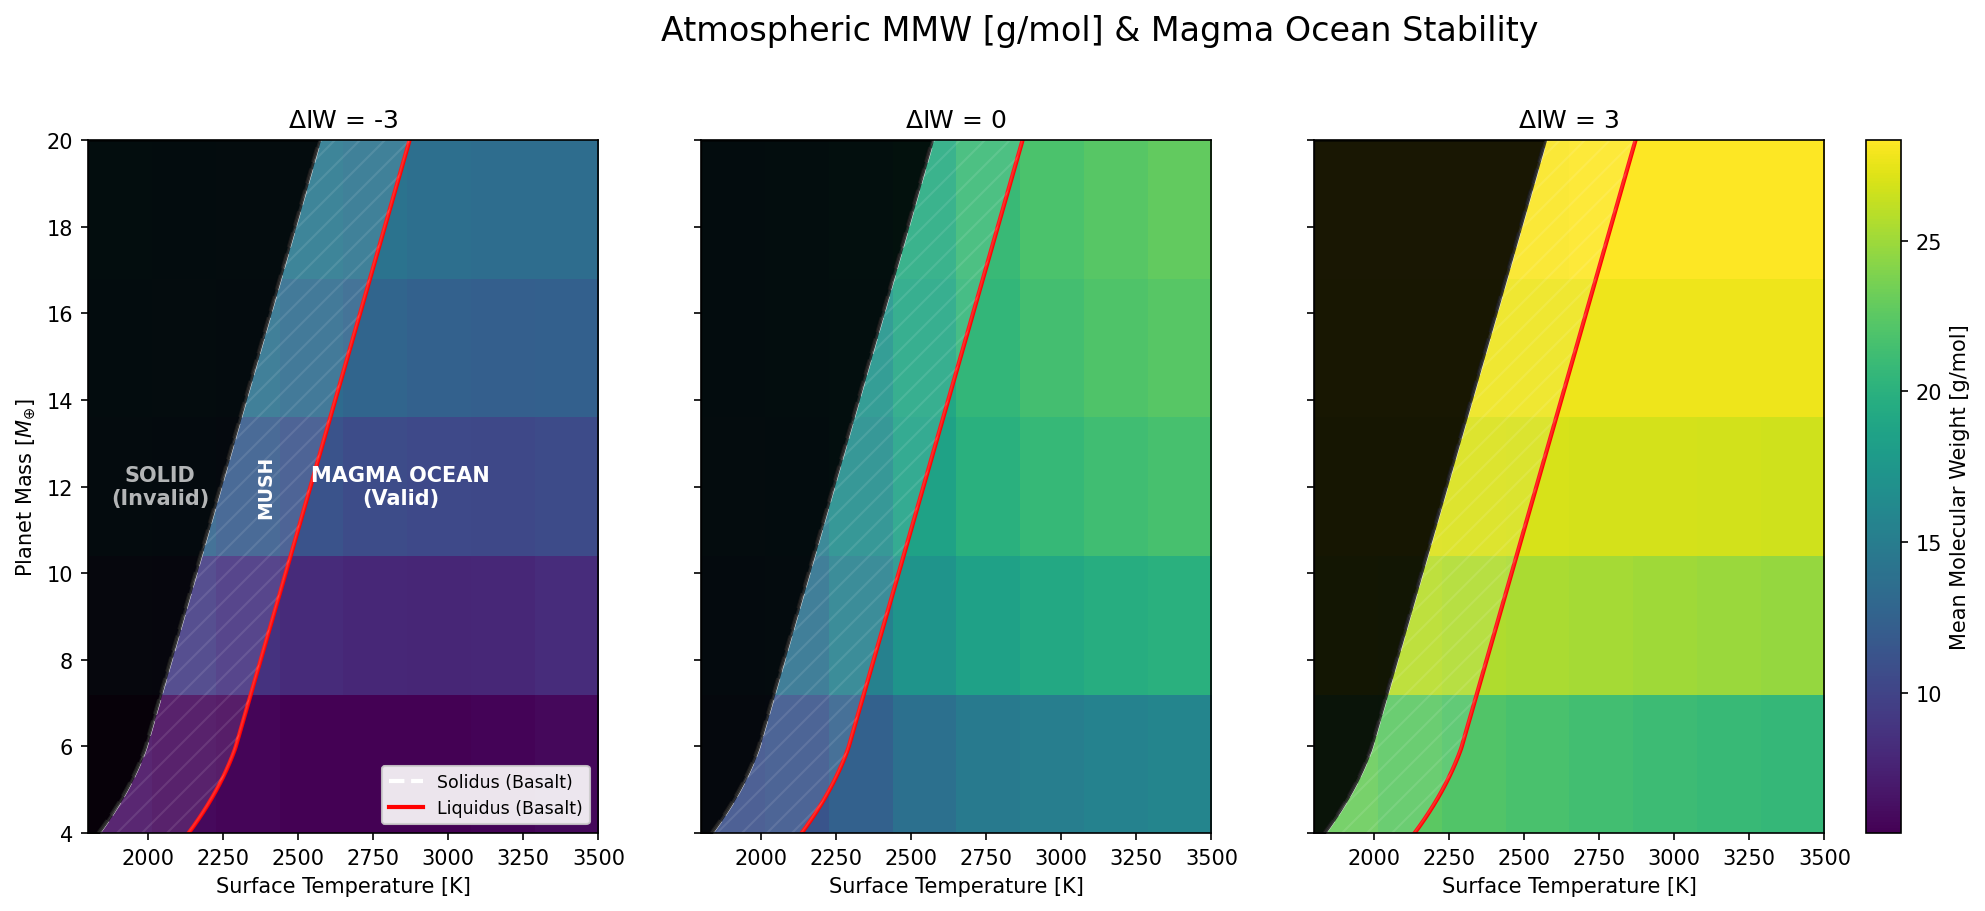

In [10]:
import logging
import numpy as np
import pandas as pd
import optimistix as optx
import matplotlib.pyplot as plt

# atmodeller imports
from atmodeller import (
    InteriorAtmosphere,
    Planet,
    SolverParameters,
    debug_logger,
)
from atmodeller.thermodata import IronWustiteBuffer
# Assuming these are available in your environment:
# from atmodeller import Species, SpeciesCollection, species_real 

# --------------------------------------------------------------------
# 1. SETUP & CONSTANTS
# --------------------------------------------------------------------
logger = debug_logger()
logger.setLevel(logging.INFO)

# Global Constants
M_EARTH = 5.972e24       # kg
R_EARTH = 6.371e6        # m
G = 6.67430e-11          # Gravitational constant

# Molar Masses for MMW calculation
MOLAR_MASSES = {
    'H2_g': 2.016, 'H2O_g': 18.015, 'CO_g': 28.010, 'CO2_g': 44.009,
    'CH4_g': 16.043, 'N2_g': 28.014, 'O2_g': 31.998, 'H3N_g': 17.031, 'He_g': 4.003,
}

# --------------------------------------------------------------------
# 2. USER-DEFINED PHYSICS FUNCTION
# --------------------------------------------------------------------

def calculate_melting_curves(mass_earth_units):
    """
    Calculate solidus and liquidus temperatures (in K) as functions of planet mass.
    Uses pressure-dependent melting relations from literature:
      - Hirschmann (2000) solidus for 0–10 GPa (adjusted for basaltic composition).
      - Linear extension ~25 K/GPa beyond 10 GPa (up to ~30+ GPa for massive planets).
      - Liquidus ~300 K above solidus (approximate constant offset for basalt).
    """
    # Convert input to numpy array for vectorized calculation
    mass_array = np.array(mass_earth_units, ndmin=1)
    
    # 1. Calculate gravity and base pressure for each mass
    M_planet = mass_array * M_EARTH                        # Planet mass [kg]
    R_planet = 1.02 * (mass_array ** 0.252) * R_EARTH      # Radius from mass-radius relation [m]
    atm_fraction = 0.016                                   # Atmosphere mass fraction (H+O+C ~1.6%)
    M_atm = atm_fraction * M_planet                        # Atmosphere mass [kg]
    g_surface = G * M_planet / (R_planet ** 2)             # Surface gravity [m/s^2]
    
    # Pressure at magma-atmosphere interface [Pa]
    P_base = M_atm * g_surface / (4 * np.pi * R_planet**2)
    P_GPa = P_base / 1e9  # convert pressure to GPa for melting formulas
    
    # 2. Solidus temperature calculation (in °C)
    # Hirschmann (2000) polynomial for peridotite solidus
    # Adjusted for basalt (lower by ~220 °C) -> baseline 900 °C at 0 GPa
    
    T_sol_peridotite_10 = -5.104*(10**2) + 132.899*10 + 1120.661  # peridotite solidus at 10 GPa (°C)
    T_sol_basalt_10 = T_sol_peridotite_10 - 220.661               # basalt-adjusted solidus at 10 GPa (°C)
    
    # Apply piecewise: if P <= 10 GPa use quadratic, if > 10 GPa use linear extension
    T_sol_C = np.where(
        P_GPa <= 10.0,
        -5.104*(P_GPa**2) + 132.899*P_GPa + 900.0,  # (°C) Hirschmann 2000 basaltic solidus
        T_sol_basalt_10 + 25.0 * (P_GPa - 10.0)     # (°C) Linear extrapolation beyond 10 GPa
    )
    
    # 3. Liquidus temperature (in °C): fixed offset above solidus
    T_liq_C = T_sol_C + 300.0  # basalt liquidus ~300 °C above solidus
    
    # Convert to Kelvin for output
    T_sol_K = T_sol_C + 273.15
    T_liq_K = T_liq_C + 273.15
    
    # If input was a scalar, return scalars instead of arrays
    if T_sol_K.size == 1:
        return float(T_sol_K), float(T_liq_K)
    return T_sol_K, T_liq_K

# --------------------------------------------------------------------
# 3. HELPER FUNCTIONS (MMW & BUDGET)
# --------------------------------------------------------------------

def calculate_mmw(df_dict):
    """Calculates Mean Molecular Weight safely."""
    mmw = 0.0
    found_any = False
    
    # Pre-calculate total moles for fallback
    total_moles = 0.0
    for key, df in df_dict.items():
        if "atmosphere_moles" in df.columns:
            total_moles += df["atmosphere_moles"].iloc[-1]

    for species_name, molar_mass in MOLAR_MASSES.items():
        if species_name in df_dict:
            df = df_dict[species_name]
            
            # Method A: Use pre-calculated volume_mixing_ratio (Preferred)
            if "volume_mixing_ratio" in df.columns:
                vmr = df["volume_mixing_ratio"].iloc[-1]
                mmw += (vmr * molar_mass)
                found_any = True
            
            # Method B: Fallback calculation
            elif "atmosphere_moles" in df.columns and total_moles > 0:
                moles = df["atmosphere_moles"].iloc[-1]
                vmr = moles / total_moles
                mmw += (vmr * molar_mass)
                found_any = True

    if not found_any or mmw == 0:
        return np.nan
        
    return mmw

# 4. SOLVER LOOP
# --------------------------------------------------------------------
solver = optx.LevenbergMarquardt
solver_parameters = SolverParameters(solver=solver)

def solve_point(T_surf, Mass_earth_units, dIW_val):
    try:
        M_planet_kg = Mass_earth_units * M_EARTH
        R_planet_m = 1.02 * (Mass_earth_units)**(0.252) * R_EARTH

        planet = Planet(
            surface_temperature=T_surf,
            planet_mass=M_planet_kg,
            surface_radius=R_planet_m,
            mantle_melt_fraction=1.0, # Assumes Full Magma Ocean
        )

        H_mass = 0.01 * M_planet_kg # Budget logic
        mass_constraints = get_enriched_budget(H_mass)
        fO2 = {"O2_g": IronWustiteBuffer(dIW_val)}
        
        # Ensure species_real is defined
        model = InteriorAtmosphere(species_real)

        model.solve(
            planet=planet,
            mass_constraints=mass_constraints,
            fugacity_constraints=fO2,
            solver_parameters=solver_parameters,
        )

        out_dict = model.output.to_dataframes()
        return calculate_mmw(out_dict)
        
    except Exception:
        return np.nan

# --- EXECUTION ---
print("Starting simulation loop...")

dIW_scenarios = [-3, 0, 3]

# Grid Definition
Ts = np.linspace(1800, 3500, 8) 
Ms_earth_units = np.linspace(4, 20, 5)

results = {}

for dIW in dIW_scenarios:
    print(f"--- Processing dIW = {dIW} ---")
    grid_data = np.zeros((len(Ms_earth_units), len(Ts)))
    
    for i, M_val in enumerate(Ms_earth_units):
        for j, T_val in enumerate(Ts):
            grid_data[i, j] = solve_point(T_val, M_val, dIW)
    results[dIW] = grid_data

# --------------------------------------------------------------------
# 5. PLOTTING WITH NEW PHYSICS
# --------------------------------------------------------------------
fig, axs = plt.subplots(1, 3, figsize=(18, 6), dpi=150, sharey=True)
fig.suptitle("Atmospheric MMW [g/mol] & Magma Ocean Stability", fontsize=16, y=1.02)

extent = [Ts.min(), Ts.max(), Ms_earth_units.min(), Ms_earth_units.max()]
all_vals = np.array([results[k] for k in results]).flatten()

# Robust Min/Max
if np.isnan(all_vals).all():
    vmin, vmax = 0, 1
else:
    vmin, vmax = np.nanmin(all_vals), np.nanmax(all_vals)

# --- CALCULATE HIGH-RES CURVES FOR PLOTTING ---
# We calculate the T_sol and T_liq for the Y-axis (Mass) array
y_fine = np.linspace(Ms_earth_units.min(), Ms_earth_units.max(), 200)
t_sol_curve, t_liq_curve = calculate_melting_curves(y_fine)

for i, dIW in enumerate(dIW_scenarios):
    ax = axs[i]
    data = results[dIW]
    
    # 1. Base Heatmap
    im = ax.imshow(
        data, 
        origin="lower", 
        aspect="auto", 
        extent=extent, 
        cmap="viridis", 
        vmin=vmin, 
        vmax=vmax
    )
    
    # 2. Draw the Lines
    # Solidus (White Dashed)
    ax.plot(t_sol_curve, y_fine, color='white', linestyle='--', linewidth=2, label='Solidus (Basalt)')
    # Liquidus (Red Solid)
    ax.plot(t_liq_curve, y_fine, color='red', linestyle='-', linewidth=2, label='Liquidus (Basalt)')

    # 3. Region Shading (Using fill_betweenx for horizontal regions)
    
    # A. IMPOSSIBLE / SOLID REGION (Left of Solidus)
    # Since the simulation assumes Melt=1.0, results here are physically invalid.
    ax.fill_betweenx(y_fine, Ts.min(), t_sol_curve, color='black', alpha=0.9, zorder=2)
    
    # B. MUSH REGION (Between Solidus and Liquidus)
    # The "Mush" zone where melt fraction < 1.0. Results are semi-valid upper bounds.
    ax.fill_betweenx(y_fine, t_sol_curve, t_liq_curve, color='white', alpha=0.1, hatch='//', zorder=2)

    # 4. Labels (First plot only)
    if i == 0:
        # Calculate visual centers for text
        y_mid = (Ms_earth_units.max() + Ms_earth_units.min()) / 2
        
        # Interpolate T values at y_mid
        t_sol_mid = np.interp(y_mid, y_fine, t_sol_curve)
        t_liq_mid = np.interp(y_mid, y_fine, t_liq_curve)
        
        # Place text
        ax.text(t_sol_mid - 200, y_mid, "SOLID\n(Invalid)", color='white', 
                ha='center', va='center', fontweight='bold', alpha=0.7)
        
        ax.text((t_sol_mid + t_liq_mid)/2, y_mid, "MUSH", color='white', 
                ha='center', va='center', fontweight='bold', fontsize=9, rotation=90)
        
        ax.text(t_liq_mid + 300, y_mid, "MAGMA OCEAN\n(Valid)", color='white', 
                ha='center', va='center', fontweight='bold')
        
        ax.legend(loc='lower right', fontsize='small', framealpha=0.9)

    ax.set_title(f"$\Delta$IW = {dIW}")
    ax.set_xlabel("Surface Temperature [K]")
    if i == 0:
        ax.set_ylabel("Planet Mass [$M_{\oplus}$]")
        
    # Ensure limits matches the solver grid
    ax.set_xlim(Ts.min(), Ts.max())
    ax.set_ylim(Ms_earth_units.min(), Ms_earth_units.max())

# Colorbar
if not np.isnan(all_vals).all():
    cbar = fig.colorbar(im, ax=axs.ravel().tolist(), pad=0.02)
    cbar.set_label("Mean Molecular Weight [g/mol]")

plt.show()

[14:22:21 - atmodeller.classes             - INFO     ] - species = ('H2O_g: CombinedRealGas, SolubilityPowerLaw', 'H2_g: CombinedRealGas, SolubilityPowerLawLog10', 'O2_g: CombinedRealGas, NoSolubility', 'CO2_g: CombinedRealGas, _CO2_basalt_dixon95', 'CO_g: CombinedRealGas, _CO_basalt_yoshioka19', 'CH4_g: CombinedRealGas, _CH4_basalt_ardia13', 'N2_g: CombinedRealGas, _N2_basalt_libourel03', 'H3N_g: RedlichKwong49, NoSolubility', 'CHN_g: RedlichKwong49, NoSolubility', 'He_g: CombinedRealGas, SolubilityPowerLaw')
[14:22:21 - atmodeller.classes             - INFO     ] - Thermodynamic data requires temperatures between 200 K and 6000 K
[14:22:21 - atmodeller.classes             - INFO     ] - reactions = {0: '2.0 H2_g + 2.0 CO_g = 1.0 CO2_g + 1.0 CH4_g',
 1: '1.0 H2_g + 1.0 CO2_g = 1.0 H2O_g + 1.0 CO_g',
 2: '1.5 H2_g + 0.5 N2_g = 1.0 H3N_g',
 3: '0.5 H2_g + 2.0 CO_g + 0.5 N2_g = 1.0 CO2_g + 1.0 CHN_g',
 4: '2.0 CO2_g = 1.0 O2_g + 2.0 CO_g'}
[14:22:21 - atmodeller.classes             - IN

Starting simulation loop...
--- Processing dIW = -3 ---


[14:22:21 - atmodeller.classes             - INFO     ] - species = ('H2O_g: CombinedRealGas, SolubilityPowerLaw', 'H2_g: CombinedRealGas, SolubilityPowerLawLog10', 'O2_g: CombinedRealGas, NoSolubility', 'CO2_g: CombinedRealGas, _CO2_basalt_dixon95', 'CO_g: CombinedRealGas, _CO_basalt_yoshioka19', 'CH4_g: CombinedRealGas, _CH4_basalt_ardia13', 'N2_g: CombinedRealGas, _N2_basalt_libourel03', 'H3N_g: RedlichKwong49, NoSolubility', 'CHN_g: RedlichKwong49, NoSolubility', 'He_g: CombinedRealGas, SolubilityPowerLaw')
[14:22:21 - atmodeller.classes             - INFO     ] - Thermodynamic data requires temperatures between 200 K and 6000 K
[14:22:21 - atmodeller.classes             - INFO     ] - reactions = {0: '2.0 H2_g + 2.0 CO_g = 1.0 CO2_g + 1.0 CH4_g',
 1: '1.0 H2_g + 1.0 CO2_g = 1.0 H2O_g + 1.0 CO_g',
 2: '1.5 H2_g + 0.5 N2_g = 1.0 H3N_g',
 3: '0.5 H2_g + 2.0 CO_g + 0.5 N2_g = 1.0 CO2_g + 1.0 CHN_g',
 4: '2.0 CO2_g = 1.0 O2_g + 2.0 CO_g'}
[14:22:21 - atmodeller.classes             - IN

--- Processing dIW = 0 ---


[14:22:25 - atmodeller.classes             - INFO     ] - species = ('H2O_g: CombinedRealGas, SolubilityPowerLaw', 'H2_g: CombinedRealGas, SolubilityPowerLawLog10', 'O2_g: CombinedRealGas, NoSolubility', 'CO2_g: CombinedRealGas, _CO2_basalt_dixon95', 'CO_g: CombinedRealGas, _CO_basalt_yoshioka19', 'CH4_g: CombinedRealGas, _CH4_basalt_ardia13', 'N2_g: CombinedRealGas, _N2_basalt_libourel03', 'H3N_g: RedlichKwong49, NoSolubility', 'CHN_g: RedlichKwong49, NoSolubility', 'He_g: CombinedRealGas, SolubilityPowerLaw')
[14:22:25 - atmodeller.classes             - INFO     ] - Thermodynamic data requires temperatures between 200 K and 6000 K
[14:22:25 - atmodeller.classes             - INFO     ] - reactions = {0: '2.0 H2_g + 2.0 CO_g = 1.0 CO2_g + 1.0 CH4_g',
 1: '1.0 H2_g + 1.0 CO2_g = 1.0 H2O_g + 1.0 CO_g',
 2: '1.5 H2_g + 0.5 N2_g = 1.0 H3N_g',
 3: '0.5 H2_g + 2.0 CO_g + 0.5 N2_g = 1.0 CO2_g + 1.0 CHN_g',
 4: '2.0 CO2_g = 1.0 O2_g + 2.0 CO_g'}
[14:22:25 - atmodeller.classes             - IN

--- Processing dIW = 3 ---


[14:22:27 - atmodeller.classes             - INFO     ] - species = ('H2O_g: CombinedRealGas, SolubilityPowerLaw', 'H2_g: CombinedRealGas, SolubilityPowerLawLog10', 'O2_g: CombinedRealGas, NoSolubility', 'CO2_g: CombinedRealGas, _CO2_basalt_dixon95', 'CO_g: CombinedRealGas, _CO_basalt_yoshioka19', 'CH4_g: CombinedRealGas, _CH4_basalt_ardia13', 'N2_g: CombinedRealGas, _N2_basalt_libourel03', 'H3N_g: RedlichKwong49, NoSolubility', 'CHN_g: RedlichKwong49, NoSolubility', 'He_g: CombinedRealGas, SolubilityPowerLaw')
[14:22:27 - atmodeller.classes             - INFO     ] - Thermodynamic data requires temperatures between 200 K and 6000 K
[14:22:27 - atmodeller.classes             - INFO     ] - reactions = {0: '2.0 H2_g + 2.0 CO_g = 1.0 CO2_g + 1.0 CH4_g',
 1: '1.0 H2_g + 1.0 CO2_g = 1.0 H2O_g + 1.0 CO_g',
 2: '1.5 H2_g + 0.5 N2_g = 1.0 H3N_g',
 3: '0.5 H2_g + 2.0 CO_g + 0.5 N2_g = 1.0 CO2_g + 1.0 CHN_g',
 4: '2.0 CO2_g = 1.0 O2_g + 2.0 CO_g'}
[14:22:27 - atmodeller.classes             - IN

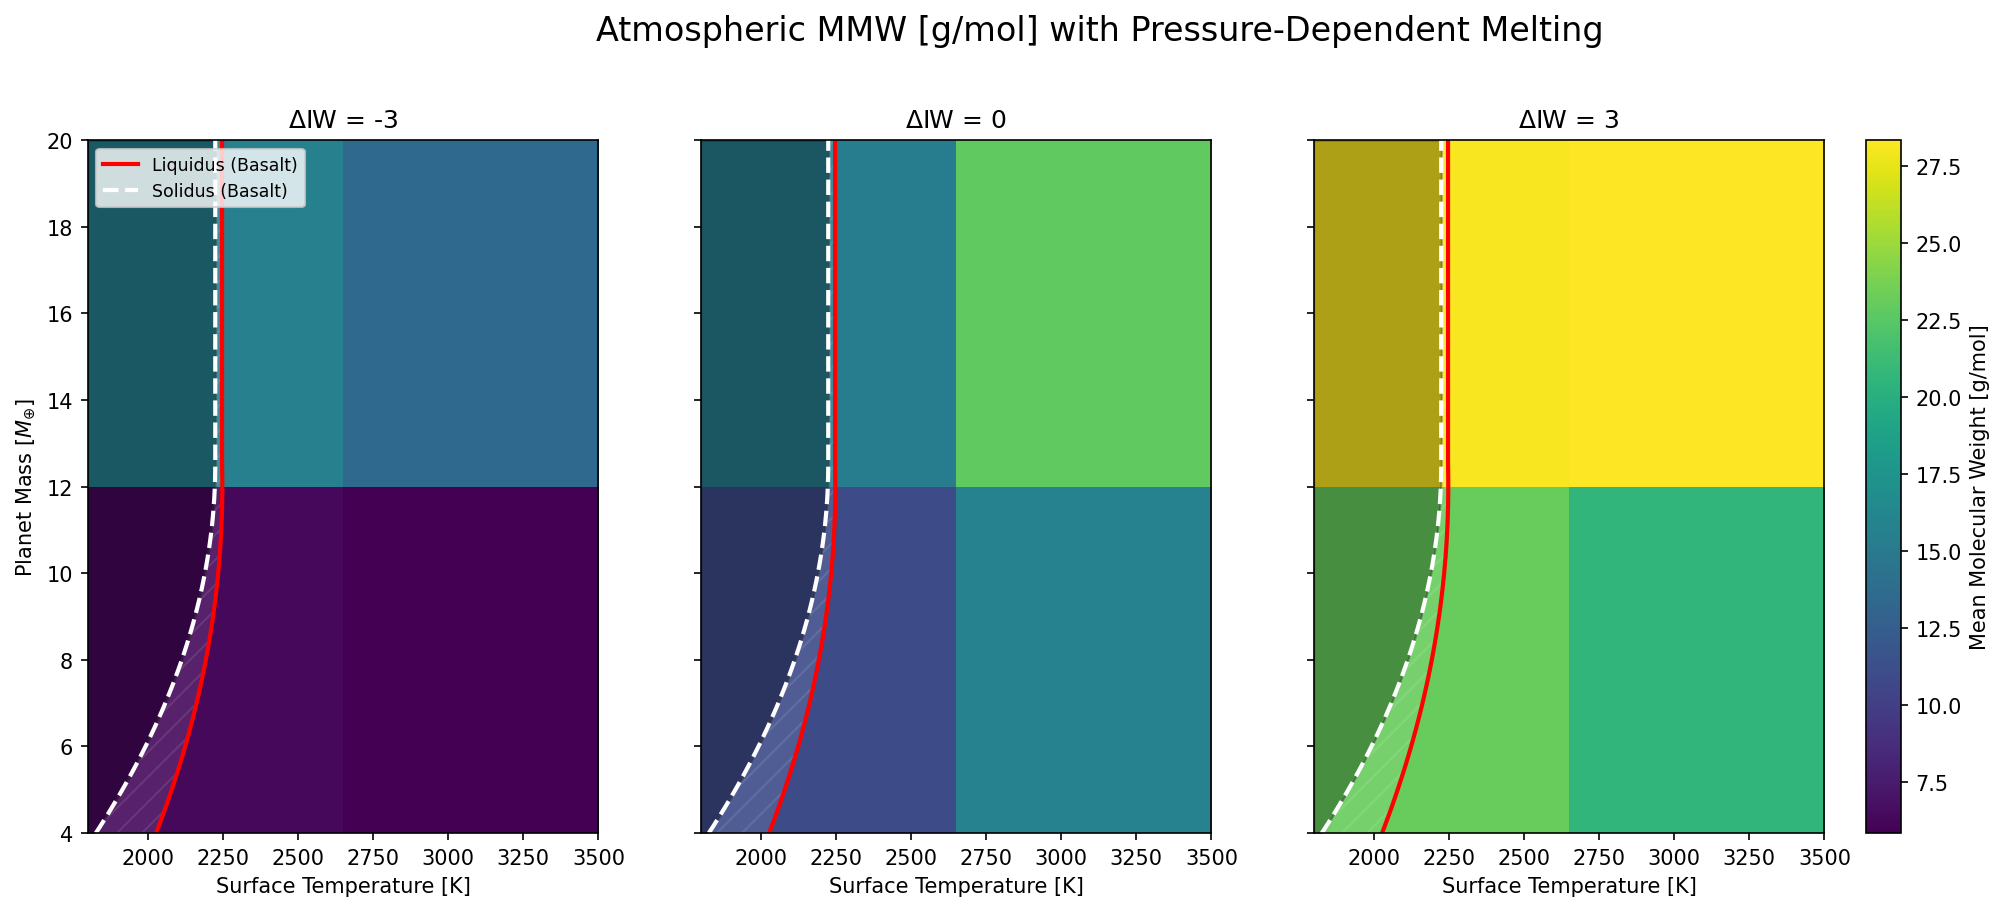

In [11]:
import logging
import numpy as np
import pandas as pd
import optimistix as optx
import matplotlib.pyplot as plt

# atmodeller imports
from atmodeller import (
    InteriorAtmosphere,
    Planet,
    SolverParameters,
    debug_logger,
)
from atmodeller.thermodata import IronWustiteBuffer
# Ensure you import your actual SpeciesCollection (species_real, etc.)
# from atmodeller import Species, SpeciesCollection, species_real 

# --------------------------------------------------------------------
# 1. SETUP
# --------------------------------------------------------------------
logger = debug_logger()
logger.setLevel(logging.INFO)

M_EARTH = 5.972e24
R_EARTH = 6.371e6
G = 6.674e-11  # gravitational constant (m^3 kg^-1 s^-2)

MOLAR_MASSES = {
    'H2_g': 2.016, 'H2O_g': 18.015, 'CO_g': 28.010, 'CO2_g': 44.009,
    'CH4_g': 16.043, 'N2_g': 28.014, 'O2_g': 31.998, 'H3N_g': 17.031, 'He_g': 4.003,
}

# --------------------------------------------------------------------
# 2. HELPER FUNCTIONS
# --------------------------------------------------------------------

def calculate_mmw(df_dict):
    """Calculates Mean Molecular Weight safely."""
    mmw = 0.0
    found_any = False
    
    # Pre-calculate total moles for fallback
    total_moles = 0.0
    for key, df in df_dict.items():
        if "atmosphere_moles" in df.columns:
            total_moles += df["atmosphere_moles"].iloc[-1]

    for species_name, molar_mass in MOLAR_MASSES.items():
        if species_name in df_dict:
            df = df_dict[species_name]
            
            # Method A: Use pre-calculated volume_mixing_ratio
            if "volume_mixing_ratio" in df.columns:
                vmr = df["volume_mixing_ratio"].iloc[-1]
                mmw += (vmr * molar_mass)
                found_any = True
            
            # Method B: Fallback manual calculation
            elif "atmosphere_moles" in df.columns and total_moles > 0:
                moles = df["atmosphere_moles"].iloc[-1]
                vmr = moles / total_moles
                mmw += (vmr * molar_mass)
                found_any = True

    if not found_any or mmw == 0:
        return np.nan
    return mmw

def calculate_melting_curves(df_dict):

    for key, df in df_dict.items():
        if "pressure" in df.columns:
            P_surface = df['pressure'].iloc[-1]

    
    P_GPa = P_surface / 1e4
    P_GPa = np.clip(P_GPa, 0, 13.0)
    
    # Calculate melting temperatures using Hirschmann (2000) fit (convert °C to K)
    T_solidus_C = 1085.7 + 132.9 * P_GPa - 5.1 * (P_GPa ** 2)
    T_liquidus_C = 1475.0 + 80.0  * P_GPa - 3.2 * (P_GPa ** 2)
    T_solidus_K = T_solidus_C + 273.15
    T_liquidus_K = T_liquidus_C + 273.15
    return T_solidus_K, T_liquidus_K

# --------------------------------------------------------------------
# 3. SOLVER
# --------------------------------------------------------------------
solver = optx.LevenbergMarquardt
solver_parameters = SolverParameters(solver=solver)

def solve_point(T_surf, Mass_earth_units, dIW_val):
    try:
        M_planet_kg = Mass_earth_units * M_EARTH
        R_planet_m = 1.02 * (Mass_earth_units)**(0.252) * R_EARTH

        planet = Planet(
            surface_temperature=T_surf,
            planet_mass=M_planet_kg,
            surface_radius=R_planet_m,
            mantle_melt_fraction=1.0, 
        )

        H_mass = 0.01 * M_planet_kg
        mass_constraints = get_enriched_budget(H_mass)
        fO2 = {"O2_g": IronWustiteBuffer(dIW_val)}
        
        # Ensure 'species_real' is defined in your scope
        model = InteriorAtmosphere(species_real)

        model.solve(
            planet=planet,
            mass_constraints=mass_constraints,
            fugacity_constraints=fO2,
            solver_parameters=solver_parameters,
        )

        out_dict = model.output.to_dataframes()
        lines = calculate_melting_curves(out_dict)
        return lines, calculate_mmw(out_dict)
    except Exception as e:
        # On failure, return NaN
        return np.nan

def lines(
# --------------------------------------------------------------------
# 4. LOOP & PLOT
# --------------------------------------------------------------------
print("Starting simulation loop...")

dIW_scenarios = [-3, 0, 3]

# Temperature range: 1800 K to 3500 K
Ts = np.linspace(1800, 3500, 2) 
Ms_earth_units = np.linspace(4, 20, 2)

results = {}

for dIW in dIW_scenarios:
    print(f"--- Processing dIW = {dIW} ---")
    grid_data = np.zeros((len(Ms_earth_units), len(Ts)))
    for i, M_val in enumerate(Ms_earth_units):
        for j, T_val in enumerate(Ts):
            lines, val = solve_point(T_val, M_val, dIW)
            grid_data[i, j] = val
    results[dIW] = grid_data

# Plotting
fig, axs = plt.subplots(1, 3, figsize=(18, 6), dpi=150, sharey=True)
fig.suptitle("Atmospheric MMW [g/mol] with Pressure-Dependent Melting", fontsize=16, y=1.02)

extent = [Ts.min(), Ts.max(), Ms_earth_units.min(), Ms_earth_units.max()]
all_vals = np.array([results[k] for k in results]).flatten()

if np.isnan(all_vals).all():
    vmin, vmax = 0, 1
else:
    vmin, vmax = np.nanmin(all_vals), np.nanmax(all_vals)

# Calculate melting curves for plotting
y_axis_masses = np.linspace(Ms_earth_units.min(), Ms_earth_units.max(), 100)
t_sol_curve, t_liq_curve = calculate_melting_curves(y_axis_masses)

for i, dIW in enumerate(dIW_scenarios):
    ax = axs[i]
    data = results[dIW]
    im = ax.imshow(data, origin="lower", aspect="auto", extent=extent, cmap="viridis", vmin=vmin, vmax=vmax)
    
    # Plot solidus and liquidus curves (mass-dependent)
    ax.plot(t_liq_curve, y_axis_masses, color='red',   linewidth=2, linestyle='-',  label='Liquidus (Basalt)')
    ax.plot(t_sol_curve, y_axis_masses, color='white', linewidth=2, linestyle='--', label='Solidus (Basalt)')
    # Shade the region between solidus and liquidus ("mush" region)
    ax.fill_betweenx(y_axis_masses, t_sol_curve, t_liq_curve, color='white', alpha=0.1, hatch='//')
    # Shade the fully solid region (left of solidus)
    ax.fill_betweenx(y_axis_masses, Ts.min(), t_sol_curve, color='black', alpha=0.3)

    ax.set_title(f"$\\Delta$IW = {dIW}")
    ax.set_xlabel("Surface Temperature [K]")
    if i == 0:
        ax.set_ylabel("Planet Mass [$M_{\\oplus}$]")
        ax.legend(loc='upper left', fontsize='small')
    ax.set_xlim(1800, 3500)  # match temperature axis to solver range

if not np.isnan(all_vals).all():
    cbar = fig.colorbar(im, ax=axs.ravel().tolist(), pad=0.02)
    cbar.set_label("Mean Molecular Weight [g/mol]")

plt.show()


[15:02:56 - atmodeller.classes             - INFO     ] - species = ('H2O_g: CombinedRealGas, SolubilityPowerLaw', 'H2_g: CombinedRealGas, SolubilityPowerLawLog10', 'O2_g: CombinedRealGas, NoSolubility', 'CO2_g: CombinedRealGas, _CO2_basalt_dixon95', 'CO_g: CombinedRealGas, _CO_basalt_yoshioka19', 'CH4_g: CombinedRealGas, _CH4_basalt_ardia13', 'N2_g: CombinedRealGas, _N2_basalt_libourel03', 'H3N_g: RedlichKwong49, NoSolubility', 'CHN_g: RedlichKwong49, NoSolubility', 'He_g: CombinedRealGas, SolubilityPowerLaw')
[15:02:56 - atmodeller.classes             - INFO     ] - Thermodynamic data requires temperatures between 200 K and 6000 K
[15:02:56 - atmodeller.classes             - INFO     ] - reactions = {0: '2.0 H2_g + 2.0 CO_g = 1.0 CO2_g + 1.0 CH4_g',
 1: '1.0 H2_g + 1.0 CO2_g = 1.0 H2O_g + 1.0 CO_g',
 2: '1.5 H2_g + 0.5 N2_g = 1.0 H3N_g',
 3: '0.5 H2_g + 2.0 CO_g + 0.5 N2_g = 1.0 CO2_g + 1.0 CHN_g',
 4: '2.0 CO2_g = 1.0 O2_g + 2.0 CO_g'}
[15:02:56 - atmodeller.classes             - IN

Starting simulation loop...
--- Processing dIW = -3 ---


[15:03:32 - atmodeller.classes             - INFO     ] - Solve complete: 1 (100.00%) successful model(s)
[15:03:32 - atmodeller.classes             - INFO     ] - Solver steps (max) = 66
[15:03:32 - atmodeller.output_core         - INFO     ] - Computing to_dataframes output
[15:03:32 - atmodeller.output_core         - INFO     ] - Computing asdict output
[15:03:36 - atmodeller.classes             - INFO     ] - species = ('H2O_g: CombinedRealGas, SolubilityPowerLaw', 'H2_g: CombinedRealGas, SolubilityPowerLawLog10', 'O2_g: CombinedRealGas, NoSolubility', 'CO2_g: CombinedRealGas, _CO2_basalt_dixon95', 'CO_g: CombinedRealGas, _CO_basalt_yoshioka19', 'CH4_g: CombinedRealGas, _CH4_basalt_ardia13', 'N2_g: CombinedRealGas, _N2_basalt_libourel03', 'H3N_g: RedlichKwong49, NoSolubility', 'CHN_g: RedlichKwong49, NoSolubility', 'He_g: CombinedRealGas, SolubilityPowerLaw')
[15:03:36 - atmodeller.classes             - INFO     ] - Thermodynamic data requires temperatures between 200 K and 6000 K


1.0


[15:03:36 - atmodeller.classes             - INFO     ] - species = ('H2O_g: CombinedRealGas, SolubilityPowerLaw', 'H2_g: CombinedRealGas, SolubilityPowerLawLog10', 'O2_g: CombinedRealGas, NoSolubility', 'CO2_g: CombinedRealGas, _CO2_basalt_dixon95', 'CO_g: CombinedRealGas, _CO_basalt_yoshioka19', 'CH4_g: CombinedRealGas, _CH4_basalt_ardia13', 'N2_g: CombinedRealGas, _N2_basalt_libourel03', 'H3N_g: RedlichKwong49, NoSolubility', 'CHN_g: RedlichKwong49, NoSolubility', 'He_g: CombinedRealGas, SolubilityPowerLaw')
[15:03:36 - atmodeller.classes             - INFO     ] - Thermodynamic data requires temperatures between 200 K and 6000 K
[15:03:36 - atmodeller.classes             - INFO     ] - reactions = {0: '2.0 H2_g + 2.0 CO_g = 1.0 CO2_g + 1.0 CH4_g',
 1: '1.0 H2_g + 1.0 CO2_g = 1.0 H2O_g + 1.0 CO_g',
 2: '1.5 H2_g + 0.5 N2_g = 1.0 H3N_g',
 3: '0.5 H2_g + 2.0 CO_g + 0.5 N2_g = 1.0 CO2_g + 1.0 CHN_g',
 4: '2.0 CO2_g = 1.0 O2_g + 2.0 CO_g'}
[15:03:36 - atmodeller.classes             - IN

...

[15:03:42 - atmodeller.classes             - INFO     ] - species = ('H2O_g: CombinedRealGas, SolubilityPowerLaw', 'H2_g: CombinedRealGas, SolubilityPowerLawLog10', 'O2_g: CombinedRealGas, NoSolubility', 'CO2_g: CombinedRealGas, _CO2_basalt_dixon95', 'CO_g: CombinedRealGas, _CO_basalt_yoshioka19', 'CH4_g: CombinedRealGas, _CH4_basalt_ardia13', 'N2_g: CombinedRealGas, _N2_basalt_libourel03', 'H3N_g: RedlichKwong49, NoSolubility', 'CHN_g: RedlichKwong49, NoSolubility', 'He_g: CombinedRealGas, SolubilityPowerLaw')
[15:03:42 - atmodeller.classes             - INFO     ] - Thermodynamic data requires temperatures between 200 K and 6000 K
[15:03:42 - atmodeller.classes             - INFO     ] - reactions = {0: '2.0 H2_g + 2.0 CO_g = 1.0 CO2_g + 1.0 CH4_g',
 1: '1.0 H2_g + 1.0 CO2_g = 1.0 H2O_g + 1.0 CO_g',
 2: '1.5 H2_g + 0.5 N2_g = 1.0 H3N_g',
 3: '0.5 H2_g + 2.0 CO_g + 0.5 N2_g = 1.0 CO2_g + 1.0 CHN_g',
 4: '2.0 CO2_g = 1.0 O2_g + 2.0 CO_g'}
[15:03:42 - atmodeller.classes             - IN

1.0


[15:03:43 - atmodeller.classes             - INFO     ] - species = ('H2O_g: CombinedRealGas, SolubilityPowerLaw', 'H2_g: CombinedRealGas, SolubilityPowerLawLog10', 'O2_g: CombinedRealGas, NoSolubility', 'CO2_g: CombinedRealGas, _CO2_basalt_dixon95', 'CO_g: CombinedRealGas, _CO_basalt_yoshioka19', 'CH4_g: CombinedRealGas, _CH4_basalt_ardia13', 'N2_g: CombinedRealGas, _N2_basalt_libourel03', 'H3N_g: RedlichKwong49, NoSolubility', 'CHN_g: RedlichKwong49, NoSolubility', 'He_g: CombinedRealGas, SolubilityPowerLaw')
[15:03:43 - atmodeller.classes             - INFO     ] - Thermodynamic data requires temperatures between 200 K and 6000 K
[15:03:43 - atmodeller.classes             - INFO     ] - reactions = {0: '2.0 H2_g + 2.0 CO_g = 1.0 CO2_g + 1.0 CH4_g',
 1: '1.0 H2_g + 1.0 CO2_g = 1.0 H2O_g + 1.0 CO_g',
 2: '1.5 H2_g + 0.5 N2_g = 1.0 H3N_g',
 3: '0.5 H2_g + 2.0 CO_g + 0.5 N2_g = 1.0 CO2_g + 1.0 CHN_g',
 4: '2.0 CO2_g = 1.0 O2_g + 2.0 CO_g'}
[15:03:43 - atmodeller.classes             - IN

1.0
1.0


/var/folders/l6/yw7hsmzx1czfjt3n32sfq_w00000gn/T/ipykernel_56833/1828209167.py:214: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


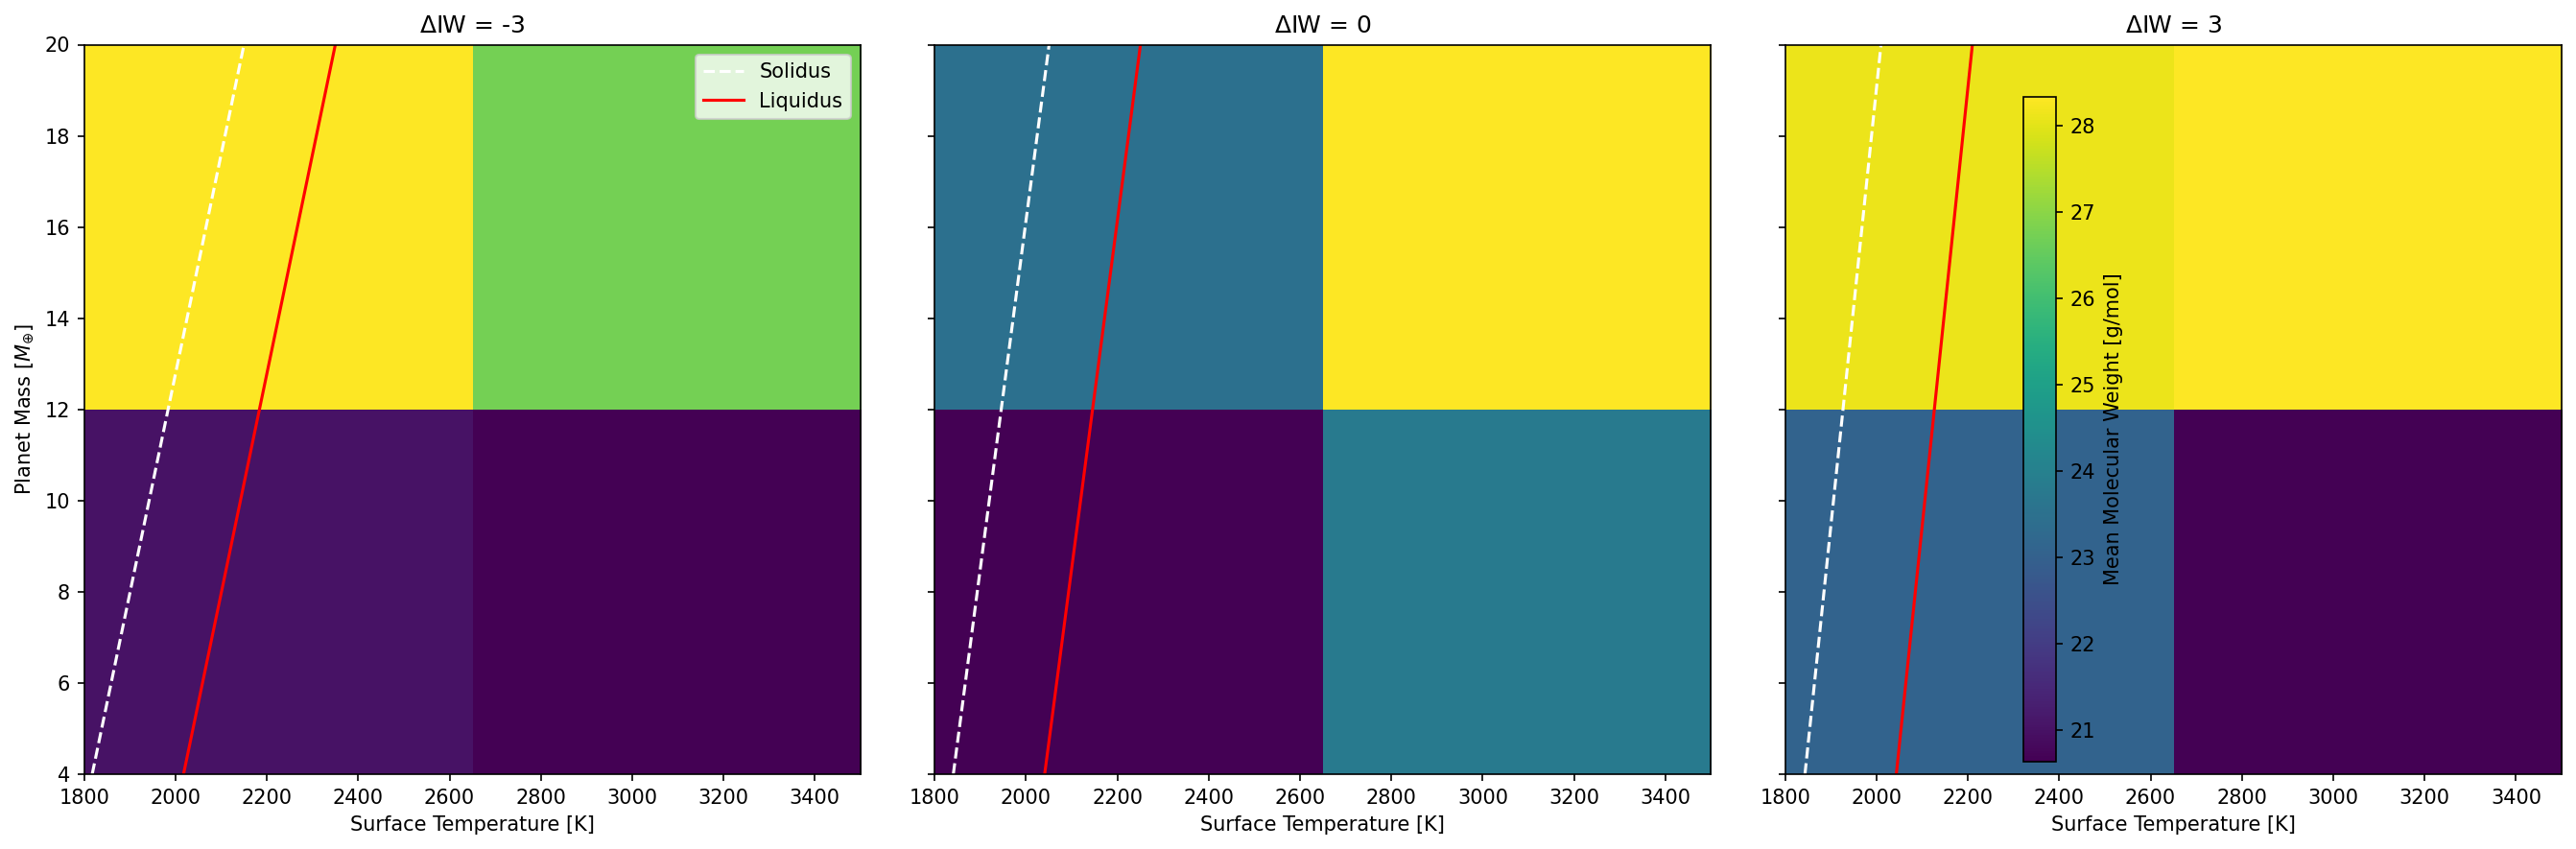

In [5]:
import logging
import numpy as np
import pandas as pd
import optimistix as optx
import matplotlib.pyplot as plt

# atmodeller imports
from atmodeller import (
    InteriorAtmosphere,
    Planet,
    SolverParameters,
    debug_logger,
)
from atmodeller.thermodata import IronWustiteBuffer

# --------------------------------------------------------------------
# YOU MUST DEFINE THESE IN YOUR ENVIRONMENT:
#   species_real
#   get_enriched_budget
# --------------------------------------------------------------------

# logger
logger = debug_logger()
logger.setLevel(logging.INFO)

# constants
M_EARTH = 5.972e24
R_EARTH = 6.371e6
G = 6.674e-11

MOLAR_MASSES = {
    'H2_g': 2.016, 'H2O_g': 18.015, 'CO_g': 28.010, 'CO2_g': 44.009,
    'CH4_g': 16.043, 'N2_g': 28.014, 'O2_g': 31.998, 'H3N_g': 17.031,
    'He_g': 4.003,
}

# --------------------------------------------------------------------
# 1. Helper: Calculate MMW
# --------------------------------------------------------------------

def calculate_mmw(df_dict):
    mmw = 0.0
    found_any = False

    total_moles = 0.0
    for df in df_dict.values():
        if "atmosphere_moles" in df.columns:
            total_moles += df["atmosphere_moles"].iloc[-1]

    for species_name, molar_mass in MOLAR_MASSES.items():
        if species_name in df_dict:
            df = df_dict[species_name]

            if "volume_mixing_ratio" in df.columns:
                vmr = df["volume_mixing_ratio"].iloc[-1]
                mmw += vmr * molar_mass
                found_any = True

            elif "atmosphere_moles" in df.columns and total_moles > 0:
                moles = df["atmosphere_moles"].iloc[-1]
                vmr = moles / total_moles
                mmw += vmr * molar_mass
                found_any = True

    if not found_any or mmw == 0:
        return np.nan
    return mmw

# --------------------------------------------------------------------
# 2. Helper: Melting Curves
# --------------------------------------------------------------------

def calculate_melting_curves(output):
    # 1. Extract surface pressure (Pa) from the atmosphere table
    atm_df = output['atmosphere']
    # If the atmosphere DataFrame has multiple entries (e.g., layers), assume the last entry is the surface:
    if hasattr(atm_df, 'iloc'):
        P_surface_pa = atm_df['pressure'].iloc[-1]
    else:
        # If atm_df is already a Series or dict-like, use it directly
        P_surface_pa = atm_df['pressure']
    
    # 2. Convert pressure from Pa to GPa
    P_surface_GPa = P_surface_pa * 1e-4
    
    # 3a. Calculate solidus (in °C) using Hirschmann (2000) polynomial fit:contentReference[oaicite:5]{index=5}
    T_solidus_C = -5.104 * (P_surface_GPa**2) + 132.899 * P_surface_GPa + 1120.661
    # Convert solidus to Kelvin
    T_solidus_K = T_solidus_C + 273.15
    
    # 3b. Calculate liquidus (in K), assuming ~200 K above solidus at these pressures:contentReference[oaicite:6]{index=6}
    T_liquidus_K = T_solidus_K + 200.0
    
    # 4. Return the melting temperatures in Kelvin
    return T_solidus_K, T_liquidus_K



# --------------------------------------------------------------------
# 3. Solver
# --------------------------------------------------------------------

solver = optx.LevenbergMarquardt
solver_parameters = SolverParameters(solver=solver)

def solve_point(T_surf, Mass_earth_units, dIW_val):
    """Return (solidus_K, liquidus_K, mean_molecular_weight)."""

    try:
        M_planet_kg = Mass_earth_units * M_EARTH
        R_planet_m = 1.02 * (Mass_earth_units)**0.252 * R_EARTH

        planet = Planet(
            surface_temperature=T_surf,
            planet_mass=M_planet_kg,
            surface_radius=R_planet_m,
        )

        # Required from your environment
        H_mass = 0.01 * M_planet_kg
        mass_constraints = get_enriched_budget(H_mass)

        fO2 = {"O2_g": IronWustiteBuffer(dIW_val)}

        model = InteriorAtmosphere(species_real)

        model.solve(
            planet=planet,
            mass_constraints=mass_constraints,
            fugacity_constraints=fO2,
            solver_parameters=solver_parameters,
        )

        out_dict = model.output.to_dataframes()

        df_planet = out_dict['planet']
        mmf = df_planet['mantle_melt_fraction'].iloc[-1]
        print(mmf)
        solidus_K, liquidus_K = calculate_melting_curves(out_dict)
        mmw = calculate_mmw(out_dict)

        return solidus_K, liquidus_K, mmw

    except Exception as e:
        print("solve_point failed:", e)
        return np.nan, np.nan, np.nan


# --------------------------------------------------------------------
# 4. Run grid
# --------------------------------------------------------------------

dIW_scenarios = [-3, 0, 3]

Ts = np.linspace(1800, 3500, 2)
Ms_earth_units = np.linspace(4, 20, 2)

solidus_grid = {dIW: np.zeros((len(Ms_earth_units), len(Ts))) for dIW in dIW_scenarios}
liquidus_grid = {dIW: np.zeros((len(Ms_earth_units), len(Ts))) for dIW in dIW_scenarios}
mmw_grid = {dIW: np.zeros((len(Ms_earth_units), len(Ts))) for dIW in dIW_scenarios}

print("Starting simulation loop...")

for dIW in dIW_scenarios:
    print(f"--- Processing dIW = {dIW} ---")

    for i, M_val in enumerate(Ms_earth_units):
        for j, T_val in enumerate(Ts):

            solidus, liquidus, mmw = solve_point(T_val, M_val, dIW)

            solidus_grid[dIW][i, j] = solidus
            liquidus_grid[dIW][i, j] = liquidus
            mmw_grid[dIW][i, j] = mmw


# --------------------------------------------------------------------
# 5. Plot MMW
# --------------------------------------------------------------------

fig, axs = plt.subplots(1, 3, figsize=(18, 6), dpi=150, sharey=True)

extent = [Ts.min(), Ts.max(), Ms_earth_units.min(), Ms_earth_units.max()]

for idx, dIW in enumerate(dIW_scenarios):

    ax = axs[idx]
    data = mmw_grid[dIW]

    im = ax.imshow(
        data,
        origin="lower",
        extent=extent,
        aspect="auto",
        cmap="viridis"
    )

    # extract melt curves vs mass at mid-temperature slice
    mid_j = len(Ts) // 2
    sol_curve = solidus_grid[dIW][:, mid_j]
    liq_curve = liquidus_grid[dIW][:, mid_j]

    ax.plot(sol_curve, Ms_earth_units, "w--", label="Solidus")
    ax.plot(liq_curve, Ms_earth_units, "r-",  label="Liquidus")

    ax.set_title(r"$\Delta$IW = " + str(dIW))
    ax.set_xlabel("Surface Temperature [K]")
    if idx == 0:
        ax.set_ylabel(r"Planet Mass [$M_{\oplus}$]")
        ax.legend()

fig.colorbar(im, ax=axs, location="right", pad=0.02, label="Mean Molecular Weight [g/mol]")

plt.tight_layout()
plt.show()


[14:53:41 - atmodeller.classes             - INFO     ] - species = ('H2O_g: CombinedRealGas, SolubilityPowerLaw', 'H2_g: CombinedRealGas, SolubilityPowerLawLog10', 'O2_g: CombinedRealGas, NoSolubility', 'CO2_g: CombinedRealGas, _CO2_basalt_dixon95', 'CO_g: CombinedRealGas, _CO_basalt_yoshioka19', 'CH4_g: CombinedRealGas, _CH4_basalt_ardia13', 'N2_g: CombinedRealGas, _N2_basalt_libourel03', 'H3N_g: RedlichKwong49, NoSolubility', 'CHN_g: RedlichKwong49, NoSolubility', 'He_g: CombinedRealGas, SolubilityPowerLaw')
[14:53:41 - atmodeller.classes             - INFO     ] - Thermodynamic data requires temperatures between 200 K and 6000 K
[14:53:41 - atmodeller.classes             - INFO     ] - reactions = {0: '2.0 H2_g + 2.0 CO_g = 1.0 CO2_g + 1.0 CH4_g',
 1: '1.0 H2_g + 1.0 CO2_g = 1.0 H2O_g + 1.0 CO_g',
 2: '1.5 H2_g + 0.5 N2_g = 1.0 H3N_g',
 3: '0.5 H2_g + 2.0 CO_g + 0.5 N2_g = 1.0 CO2_g + 1.0 CHN_g',
 4: '2.0 CO2_g = 1.0 O2_g + 2.0 CO_g'}
[14:53:41 - atmodeller.classes             - IN

Starting simulation loop...
--- Processing dIW = -3 ---


/var/folders/l6/yw7hsmzx1czfjt3n32sfq_w00000gn/T/ipykernel_56136/3632496615.py:122: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  return float(T_solidus_K), float(T_liquidus_K)
[14:53:42 - atmodeller.classes             - INFO     ] - species = ('H2O_g: CombinedRealGas, SolubilityPowerLaw', 'H2_g: CombinedRealGas, SolubilityPowerLawLog10', 'O2_g: CombinedRealGas, NoSolubility', 'CO2_g: CombinedRealGas, _CO2_basalt_dixon95', 'CO_g: CombinedRealGas, _CO_basalt_yoshioka19', 'CH4_g: CombinedRealGas, _CH4_basalt_ardia13', 'N2_g: CombinedRealGas, _N2_basalt_libourel03', 'H3N_g: RedlichKwong49, NoSolubility', 'CHN_g: RedlichKwong49, NoSolubility', 'He_g: CombinedRealGas, SolubilityPowerLaw')
[14:53:42 - atmodeller.classes             - INFO     ] - Thermodynamic data requires temperatures between 200 K and 6000 K
[14:5

--- Processing dIW = 0 ---


[14:53:45 - atmodeller.classes             - INFO     ] - species = ('H2O_g: CombinedRealGas, SolubilityPowerLaw', 'H2_g: CombinedRealGas, SolubilityPowerLawLog10', 'O2_g: CombinedRealGas, NoSolubility', 'CO2_g: CombinedRealGas, _CO2_basalt_dixon95', 'CO_g: CombinedRealGas, _CO_basalt_yoshioka19', 'CH4_g: CombinedRealGas, _CH4_basalt_ardia13', 'N2_g: CombinedRealGas, _N2_basalt_libourel03', 'H3N_g: RedlichKwong49, NoSolubility', 'CHN_g: RedlichKwong49, NoSolubility', 'He_g: CombinedRealGas, SolubilityPowerLaw')
[14:53:45 - atmodeller.classes             - INFO     ] - Thermodynamic data requires temperatures between 200 K and 6000 K
[14:53:45 - atmodeller.classes             - INFO     ] - reactions = {0: '2.0 H2_g + 2.0 CO_g = 1.0 CO2_g + 1.0 CH4_g',
 1: '1.0 H2_g + 1.0 CO2_g = 1.0 H2O_g + 1.0 CO_g',
 2: '1.5 H2_g + 0.5 N2_g = 1.0 H3N_g',
 3: '0.5 H2_g + 2.0 CO_g + 0.5 N2_g = 1.0 CO2_g + 1.0 CHN_g',
 4: '2.0 CO2_g = 1.0 O2_g + 2.0 CO_g'}
[14:53:45 - atmodeller.classes             - IN

--- Processing dIW = 3 ---


[14:53:48 - atmodeller.classes             - INFO     ] - species = ('H2O_g: CombinedRealGas, SolubilityPowerLaw', 'H2_g: CombinedRealGas, SolubilityPowerLawLog10', 'O2_g: CombinedRealGas, NoSolubility', 'CO2_g: CombinedRealGas, _CO2_basalt_dixon95', 'CO_g: CombinedRealGas, _CO_basalt_yoshioka19', 'CH4_g: CombinedRealGas, _CH4_basalt_ardia13', 'N2_g: CombinedRealGas, _N2_basalt_libourel03', 'H3N_g: RedlichKwong49, NoSolubility', 'CHN_g: RedlichKwong49, NoSolubility', 'He_g: CombinedRealGas, SolubilityPowerLaw')
[14:53:48 - atmodeller.classes             - INFO     ] - Thermodynamic data requires temperatures between 200 K and 6000 K
[14:53:48 - atmodeller.classes             - INFO     ] - reactions = {0: '2.0 H2_g + 2.0 CO_g = 1.0 CO2_g + 1.0 CH4_g',
 1: '1.0 H2_g + 1.0 CO2_g = 1.0 H2O_g + 1.0 CO_g',
 2: '1.5 H2_g + 0.5 N2_g = 1.0 H3N_g',
 3: '0.5 H2_g + 2.0 CO_g + 0.5 N2_g = 1.0 CO2_g + 1.0 CHN_g',
 4: '2.0 CO2_g = 1.0 O2_g + 2.0 CO_g'}
[14:53:48 - atmodeller.classes             - IN

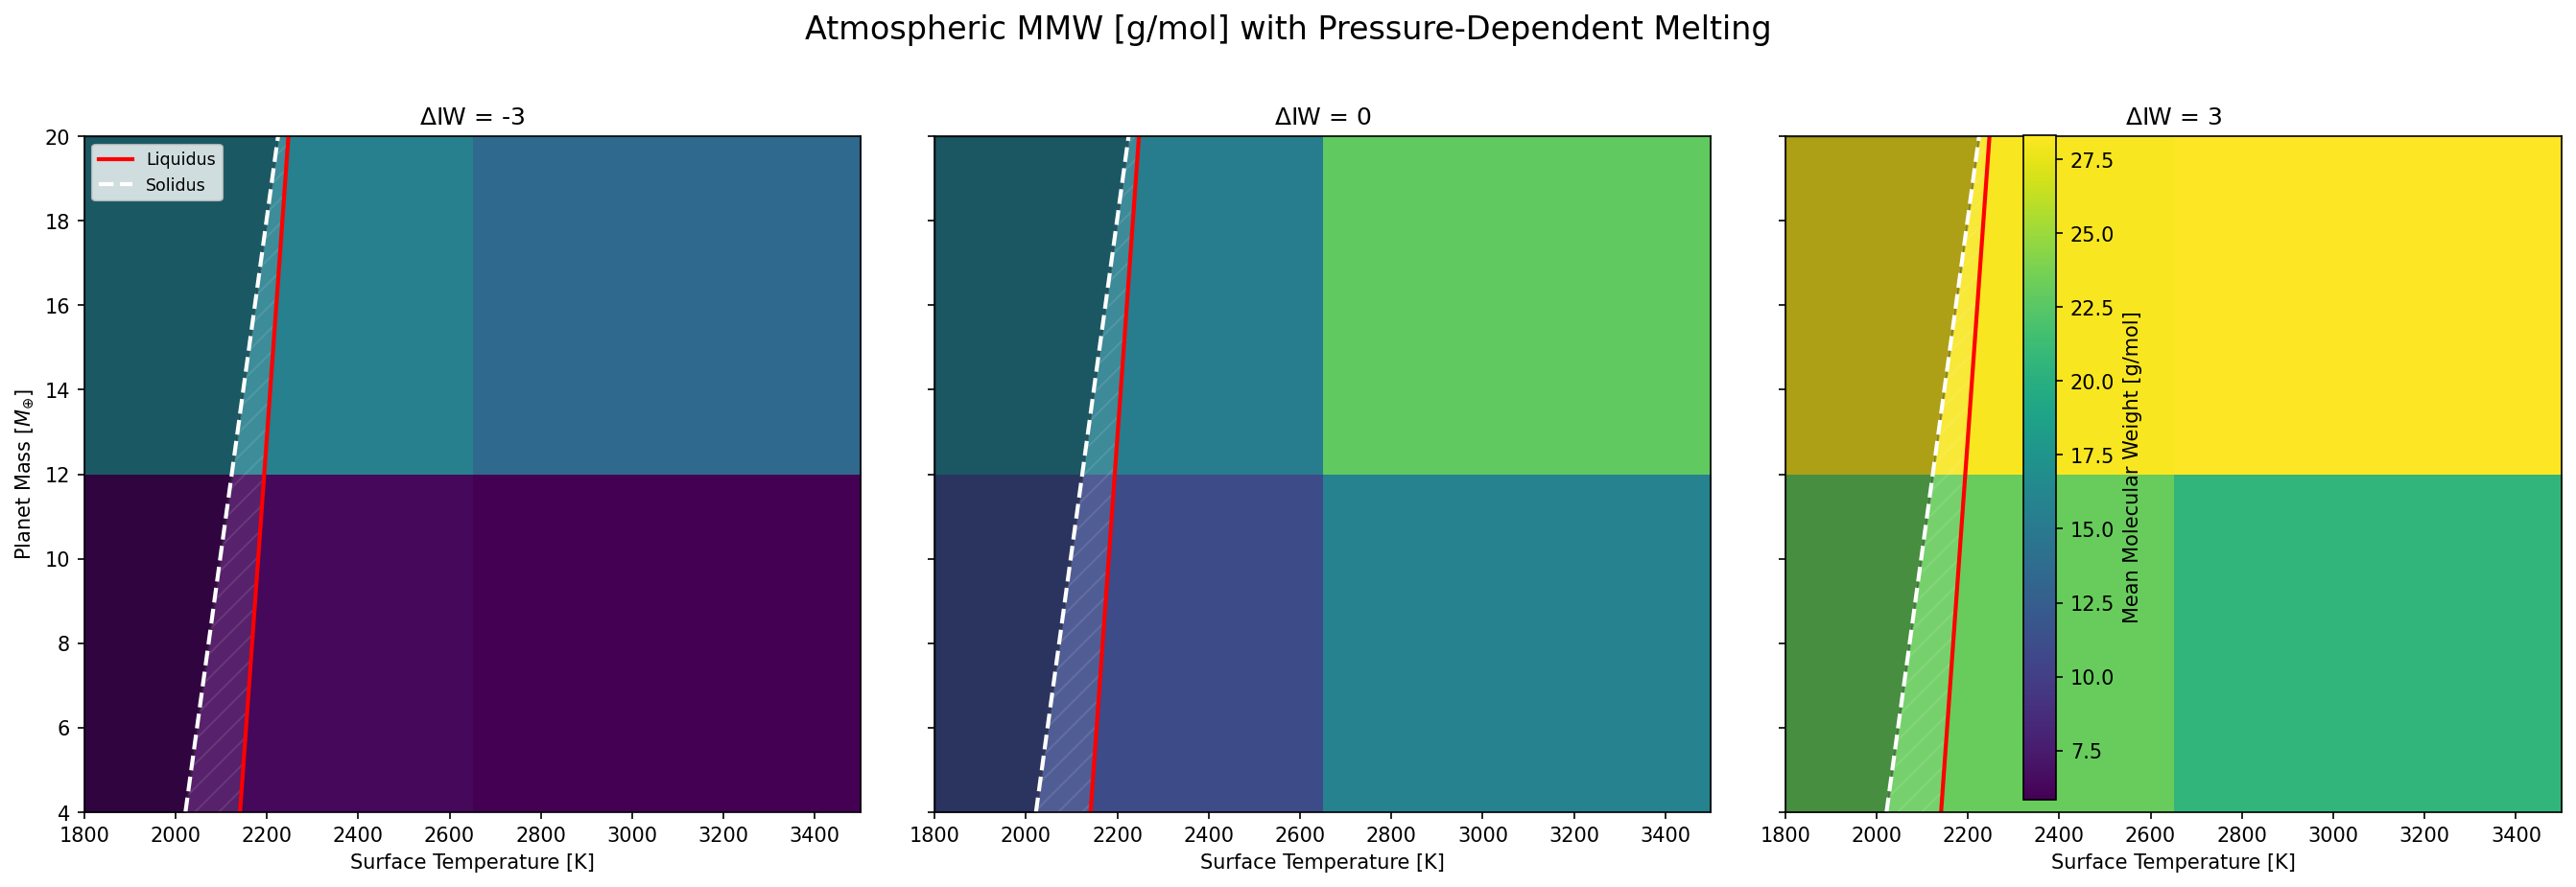

In [16]:
import logging
import numpy as np
import pandas as pd
import optimistix as optx
import matplotlib.pyplot as plt

# --------------------------------------------------------------------
# 1. ATMODELLER IMPORTS
# --------------------------------------------------------------------
from atmodeller import (
    InteriorAtmosphere,
    Planet,
    SolverParameters,
    debug_logger,
)
from atmodeller.thermodata import IronWustiteBuffer

# NOTE: You said these are defined elsewhere; they MUST exist:
# from atmodeller import species_real, get_enriched_budget

# --------------------------------------------------------------------
# 2. CONSTANTS & SETUP
# --------------------------------------------------------------------
logger = debug_logger()
logger.setLevel(logging.INFO)

M_EARTH = 5.972e24       # kg
R_EARTH = 6.371e6        # m
G = 6.67430e-11          # m^3 kg^-1 s^-2 (gravitational constant)

MOLAR_MASSES = {
    "H2_g": 2.016,
    "H2O_g": 18.015,
    "CO_g": 28.010,
    "CO2_g": 44.009,
    "CH4_g": 16.043,
    "N2_g": 28.014,
    "O2_g": 31.998,
    "H3N_g": 17.031,
    "He_g": 4.003,
}

# --------------------------------------------------------------------
# 3. HELPER FUNCTIONS
# --------------------------------------------------------------------
def calculate_mmw(df_dict):
    """
    Calculate Mean Molecular Weight [g/mol] from model output dict
    produced by model.output.to_dataframes().
    """
    mmw = 0.0
    found_any = False

    # Total moles for fallback VMR calculation
    total_moles = 0.0
    for _, df in df_dict.items():
        if "atmosphere_moles" in df.columns:
            total_moles += df["atmosphere_moles"].iloc[-1]

    for species_name, molar_mass in MOLAR_MASSES.items():
        if species_name in df_dict:
            df = df_dict[species_name]

            # Preferred: directly use volume mixing ratio if present
            if "volume_mixing_ratio" in df.columns:
                vmr = df["volume_mixing_ratio"].iloc[-1]
                mmw += vmr * molar_mass
                found_any = True

            # Fallback: compute vmr from moles / total_moles
            elif "atmosphere_moles" in df.columns and total_moles > 0.0:
                moles = df["atmosphere_moles"].iloc[-1]
                vmr = moles / total_moles
                mmw += vmr * molar_mass
                found_any = True

    if not found_any or mmw == 0.0:
        return np.nan
    return mmw


def melting_temps_from_mass(mass_earth_units, atm_fraction=0.016):
    """
    Compute solidus and liquidus temperatures (K) as a function of planet mass
    using a pressure-dependent melting relation.

    Pressure is computed from a simple atmosphere-over-magma model:
      P_base = (M_atm * g) / (4 π R^2)   [Pa]

    Then converted to GPa and fed into Hirschmann-style polynomials:
      T_solidus_C = 1085.7 + 132.9 P - 5.1 P^2
      T_liquidus_C = 1475.0 +  80.0 P - 3.2 P^2
    with P in GPa, clipped to [0, 13] GPa.
    """
    m_arr = np.array(mass_earth_units, ndmin=1)  # ensure array
    # Planet mass and radius
    M_planet = m_arr * M_EARTH
    R_planet = 1.02 * (m_arr ** 0.252) * R_EARTH  # your mass-radius relation

    # Atmosphere mass
    M_atm = atm_fraction * M_planet

    # Surface gravity
    g_surface = G * M_planet / (R_planet ** 2)

    # Base pressure [Pa]
    P_base = M_atm * g_surface / (4.0 * np.pi * R_planet ** 2)

    # Convert Pa → GPa
    P_GPa = P_base / 1e9
    P_GPa = np.clip(P_GPa, 0.0, 13.0)

    # Hirschmann-style peridotite fits (you gave these)
    T_solidus_C = 1085.7 + 132.9 * P_GPa - 5.1 * (P_GPa ** 2)
    T_liquidus_C = 1475.0 + 80.0 * P_GPa - 3.2 * (P_GPa ** 2)

    T_solidus_K = T_solidus_C + 273.15
    T_liquidus_K = T_liquidus_C + 273.15

    # Return scalars if scalar input
    if T_solidus_K.size == 1:
        return float(T_solidus_K), float(T_liquidus_K)
    return T_solidus_K, T_liquidus_K

# --------------------------------------------------------------------
# 4. SOLVER SETUP
# --------------------------------------------------------------------
solver = optx.LevenbergMarquardt
solver_parameters = SolverParameters(solver=solver)

def solve_point(T_surf, Mass_earth_units, dIW_val):
    """
    For one (T_surf, Mass, dIW):
      - build Planet
      - solve InteriorAtmosphere
      - compute:
          * T_solidus_K, T_liquidus_K  (from mass → pressure)
          * mmw                        (from model outputs)
      - return them
    """
    try:
        # Planet properties
        M_planet_kg = Mass_earth_units * M_EARTH
        R_planet_m = 1.02 * (Mass_earth_units ** 0.252) * R_EARTH

        planet = Planet(
            surface_temperature=T_surf,
            planet_mass=M_planet_kg,
            surface_radius=R_planet_m,
            mantle_melt_fraction=1.0,
        )

        # Example volatile budget (you said you have get_enriched_budget)
        H_mass = 0.01 * M_planet_kg
        mass_constraints = get_enriched_budget(H_mass)  # must exist in your scope

        # Redox / fO2
        fO2 = {"O2_g": IronWustiteBuffer(dIW_val)}

        # Model
        model = InteriorAtmosphere(species_real)  # species_real must exist

        model.solve(
            planet=planet,
            mass_constraints=mass_constraints,
            fugacity_constraints=fO2,
            solver_parameters=solver_parameters,
        )

        out_dict = model.output.to_dataframes()

        # Mean molecular weight
        mmw_val = calculate_mmw(out_dict)

        # Melting temperatures from MASS (consistent with mass used above)
        T_solidus_K, T_liquidus_K = melting_temps_from_mass(Mass_earth_units)

        return T_solidus_K, T_liquidus_K, mmw_val

    except Exception as e:
        # Debug print so you SEE why a point fails
        print(f"solve_point failed at T={T_surf}, M={Mass_earth_units}, dIW={dIW_val}: {e}")
        return np.nan, np.nan, np.nan

# --------------------------------------------------------------------
# 5. LOOP OVER GRID & STORE ARRAYS
# --------------------------------------------------------------------
print("Starting simulation loop...")

dIW_scenarios = [-3, 0, 3]

# You probably want more than 2×2, but keeping your original settings:
Ts = np.linspace(1800, 3500, 2)       # surface temperature grid [K]
Ms_earth_units = np.linspace(4, 20, 2)  # mass grid [M_earth]

# For each dIW we store:
#   - solidus[T_index, M_index]
#   - liquidus[T_index, M_index]
#   - mmw[T_index, M_index]
solidus_grid = {}
liquidus_grid = {}
mmw_grid = {}

for dIW in dIW_scenarios:
    print(f"--- Processing dIW = {dIW} ---")

    sol_data = np.zeros((len(Ms_earth_units), len(Ts)))
    liq_data = np.zeros((len(Ms_earth_units), len(Ts)))
    mmw_data = np.zeros((len(Ms_earth_units), len(Ts)))

    for i, M_val in enumerate(Ms_earth_units):
        for j, T_val in enumerate(Ts):
            T_sol, T_liq, mmw_val = solve_point(T_val, M_val, dIW)
            sol_data[i, j] = T_sol
            liq_data[i, j] = T_liq
            mmw_data[i, j] = mmw_val

    solidus_grid[dIW] = sol_data
    liquidus_grid[dIW] = liq_data
    mmw_grid[dIW] = mmw_data

# --------------------------------------------------------------------
# 6. PLOTTING
# --------------------------------------------------------------------
fig, axs = plt.subplots(1, 3, figsize=(18, 6), dpi=150, sharey=True)
fig.suptitle("Atmospheric MMW [g/mol] with Pressure-Dependent Melting", fontsize=16, y=1.02)

extent = [Ts.min(), Ts.max(), Ms_earth_units.min(), Ms_earth_units.max()]

# Collect all MMW values for shared color scale
all_mmw_vals = np.array([mmw_grid[d] for d in dIW_scenarios]).flatten()
if np.isnan(all_mmw_vals).all():
    vmin, vmax = 0.0, 1.0
else:
    vmin, vmax = np.nanmin(all_mmw_vals), np.nanmax(all_mmw_vals)

# For plotting "lines" from the stored solidus/liquidus arrays:
# We take one T-slice (e.g. j = 0, first temperature) as representative,
# because T_sol/T_liq depend only on mass in this model and are constant over T.
y_axis_masses = Ms_earth_units
for idx, dIW in enumerate(dIW_scenarios):
    ax = axs[idx]
    mmw_data = mmw_grid[dIW]

    im = ax.imshow(
        mmw_data,
        origin="lower",
        aspect="auto",
        extent=extent,
        cmap="viridis",
        vmin=vmin,
        vmax=vmax,
    )

    # Extract solidus/liquidus as arrays vs mass from precomputed grids
    sol_curve = solidus_grid[dIW][:, 0]  # first T-column
    liq_curve = liquidus_grid[dIW][:, 0]

    # Plot lines (T on x-axis, mass on y-axis)
    ax.plot(liq_curve, y_axis_masses, color="red",   linewidth=2, linestyle="-",  label="Liquidus")
    ax.plot(sol_curve, y_axis_masses, color="white", linewidth=2, linestyle="--", label="Solidus")

    # Shade mush region between solidus and liquidus
    ax.fill_betweenx(y_axis_masses, sol_curve, liq_curve, color="white", alpha=0.1, hatch="//")

    # Shade fully solid region left of solidus
    ax.fill_betweenx(y_axis_masses, Ts.min(), sol_curve, color="black", alpha=0.3)

    ax.set_title(fr"$\Delta$IW = {dIW}")
    ax.set_xlabel("Surface Temperature [K]")

    if idx == 0:
        ax.set_ylabel(r"Planet Mass [$M_{\oplus}$]")
        ax.legend(loc="upper left", fontsize="small")

    ax.set_xlim(Ts.min(), Ts.max())

# Shared colorbar for MMW
if not np.isnan(all_mmw_vals).all():
    cbar = fig.colorbar(im, ax=axs.ravel().tolist(), pad=0.02)
    cbar.set_label("Mean Molecular Weight [g/mol]")

plt.tight_layout()
plt.show()


[15:12:52 - atmodeller.classes             - INFO     ] - species = ('H2O_g: CombinedRealGas, SolubilityPowerLaw', 'H2_g: CombinedRealGas, SolubilityPowerLawLog10', 'O2_g: CombinedRealGas, NoSolubility', 'CO2_g: CombinedRealGas, _CO2_basalt_dixon95', 'CO_g: CombinedRealGas, _CO_basalt_yoshioka19', 'CH4_g: CombinedRealGas, _CH4_basalt_ardia13', 'N2_g: CombinedRealGas, _N2_basalt_libourel03', 'H3N_g: RedlichKwong49, NoSolubility', 'CHN_g: RedlichKwong49, NoSolubility', 'He_g: CombinedRealGas, SolubilityPowerLaw')
[15:12:52 - atmodeller.classes             - INFO     ] - Thermodynamic data requires temperatures between 200 K and 6000 K
[15:12:52 - atmodeller.classes             - INFO     ] - reactions = {0: '2.0 H2_g + 2.0 CO_g = 1.0 CO2_g + 1.0 CH4_g',
 1: '1.0 H2_g + 1.0 CO2_g = 1.0 H2O_g + 1.0 CO_g',
 2: '1.5 H2_g + 0.5 N2_g = 1.0 H3N_g',
 3: '0.5 H2_g + 2.0 CO_g + 0.5 N2_g = 1.0 CO2_g + 1.0 CHN_g',
 4: '2.0 CO2_g = 1.0 O2_g + 2.0 CO_g'}
[15:12:52 - atmodeller.classes             - IN

Starting simulation loop...
--- Processing dIW = -3 ---


[15:12:53 - atmodeller.classes             - INFO     ] - species = ('H2O_g: CombinedRealGas, SolubilityPowerLaw', 'H2_g: CombinedRealGas, SolubilityPowerLawLog10', 'O2_g: CombinedRealGas, NoSolubility', 'CO2_g: CombinedRealGas, _CO2_basalt_dixon95', 'CO_g: CombinedRealGas, _CO_basalt_yoshioka19', 'CH4_g: CombinedRealGas, _CH4_basalt_ardia13', 'N2_g: CombinedRealGas, _N2_basalt_libourel03', 'H3N_g: RedlichKwong49, NoSolubility', 'CHN_g: RedlichKwong49, NoSolubility', 'He_g: CombinedRealGas, SolubilityPowerLaw')
[15:12:53 - atmodeller.classes             - INFO     ] - Thermodynamic data requires temperatures between 200 K and 6000 K
[15:12:53 - atmodeller.classes             - INFO     ] - reactions = {0: '2.0 H2_g + 2.0 CO_g = 1.0 CO2_g + 1.0 CH4_g',
 1: '1.0 H2_g + 1.0 CO2_g = 1.0 H2O_g + 1.0 CO_g',
 2: '1.5 H2_g + 0.5 N2_g = 1.0 H3N_g',
 3: '0.5 H2_g + 2.0 CO_g + 0.5 N2_g = 1.0 CO2_g + 1.0 CHN_g',
 4: '2.0 CO2_g = 1.0 O2_g + 2.0 CO_g'}
[15:12:53 - atmodeller.classes             - IN

--- Processing dIW = 0 ---


[15:12:56 - atmodeller.classes             - INFO     ] - species = ('H2O_g: CombinedRealGas, SolubilityPowerLaw', 'H2_g: CombinedRealGas, SolubilityPowerLawLog10', 'O2_g: CombinedRealGas, NoSolubility', 'CO2_g: CombinedRealGas, _CO2_basalt_dixon95', 'CO_g: CombinedRealGas, _CO_basalt_yoshioka19', 'CH4_g: CombinedRealGas, _CH4_basalt_ardia13', 'N2_g: CombinedRealGas, _N2_basalt_libourel03', 'H3N_g: RedlichKwong49, NoSolubility', 'CHN_g: RedlichKwong49, NoSolubility', 'He_g: CombinedRealGas, SolubilityPowerLaw')
[15:12:56 - atmodeller.classes             - INFO     ] - Thermodynamic data requires temperatures between 200 K and 6000 K
[15:12:56 - atmodeller.classes             - INFO     ] - reactions = {0: '2.0 H2_g + 2.0 CO_g = 1.0 CO2_g + 1.0 CH4_g',
 1: '1.0 H2_g + 1.0 CO2_g = 1.0 H2O_g + 1.0 CO_g',
 2: '1.5 H2_g + 0.5 N2_g = 1.0 H3N_g',
 3: '0.5 H2_g + 2.0 CO_g + 0.5 N2_g = 1.0 CO2_g + 1.0 CHN_g',
 4: '2.0 CO2_g = 1.0 O2_g + 2.0 CO_g'}
[15:12:56 - atmodeller.classes             - IN

--- Processing dIW = 3 ---


[15:12:59 - atmodeller.classes             - INFO     ] - species = ('H2O_g: CombinedRealGas, SolubilityPowerLaw', 'H2_g: CombinedRealGas, SolubilityPowerLawLog10', 'O2_g: CombinedRealGas, NoSolubility', 'CO2_g: CombinedRealGas, _CO2_basalt_dixon95', 'CO_g: CombinedRealGas, _CO_basalt_yoshioka19', 'CH4_g: CombinedRealGas, _CH4_basalt_ardia13', 'N2_g: CombinedRealGas, _N2_basalt_libourel03', 'H3N_g: RedlichKwong49, NoSolubility', 'CHN_g: RedlichKwong49, NoSolubility', 'He_g: CombinedRealGas, SolubilityPowerLaw')
[15:12:59 - atmodeller.classes             - INFO     ] - Thermodynamic data requires temperatures between 200 K and 6000 K
[15:12:59 - atmodeller.classes             - INFO     ] - reactions = {0: '2.0 H2_g + 2.0 CO_g = 1.0 CO2_g + 1.0 CH4_g',
 1: '1.0 H2_g + 1.0 CO2_g = 1.0 H2O_g + 1.0 CO_g',
 2: '1.5 H2_g + 0.5 N2_g = 1.0 H3N_g',
 3: '0.5 H2_g + 2.0 CO_g + 0.5 N2_g = 1.0 CO2_g + 1.0 CHN_g',
 4: '2.0 CO2_g = 1.0 O2_g + 2.0 CO_g'}
[15:12:59 - atmodeller.classes             - IN

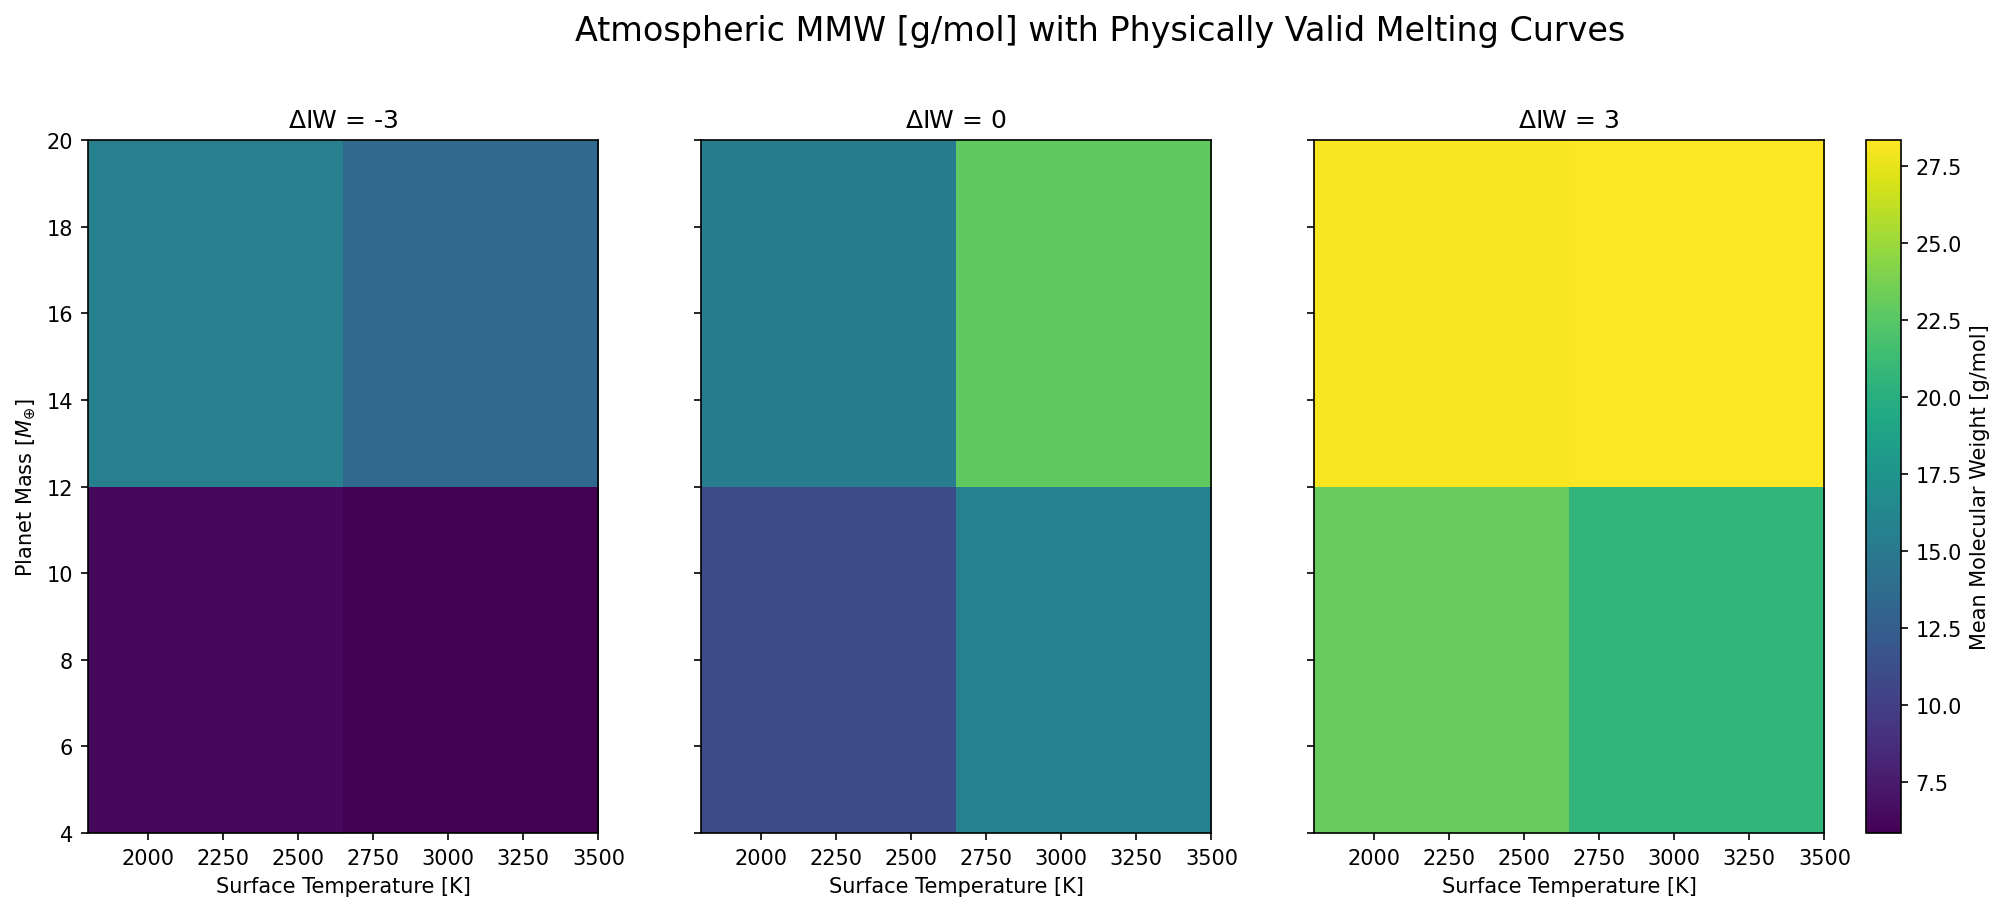

In [13]:
import logging
import numpy as np
import pandas as pd
import optimistix as optx
import matplotlib.pyplot as plt

# atmodeller imports
from atmodeller import (
    InteriorAtmosphere,
    Planet,
    SolverParameters,
    debug_logger,
)
from atmodeller.thermodata import IronWustiteBuffer
# from atmodeller import SpeciesCollection, species_real

logger = debug_logger()
logger.setLevel(logging.INFO)

M_EARTH = 5.972e24
R_EARTH = 6.371e6
G = 6.674e-11

MOLAR_MASSES = {
    'H2_g': 2.016, 'H2O_g': 18.015, 'CO_g': 28.010, 'CO2_g': 44.009,
    'CH4_g': 16.043, 'N2_g': 28.014, 'O2_g': 31.998, 'H3N_g': 17.031, 'He_g': 4.003,
}

solver = optx.LevenbergMarquardt
solver_parameters = SolverParameters(solver=solver)

def calculate_mmw(df_dict):
    mmw = 0.0
    found_any = False
    total_moles = 0.0
    for key, df in df_dict.items():
        if "atmosphere_moles" in df.columns:
            total_moles += df["atmosphere_moles"].iloc[-1]

    for species_name, molar_mass in MOLAR_MASSES.items():
        if species_name in df_dict:
            df = df_dict[species_name]
            if "volume_mixing_ratio" in df.columns:
                vmr = df["volume_mixing_ratio"].iloc[-1]
                mmw += (vmr * molar_mass)
                found_any = True
            elif "atmosphere_moles" in df.columns and total_moles > 0:
                moles = df["atmosphere_moles"].iloc[-1]
                vmr = moles / total_moles
                mmw += (vmr * molar_mass)
                found_any = True

    return mmw if found_any and mmw > 0 else np.nan

def compute_melting_temps(output):
    atm_df = output['atmosphere']
    P_surface_pa = atm_df['pressure'].iloc[-1]
    P_surface_GPa = P_surface_pa * 1e-4
    T_solidus_C = -5.104 * (P_surface_GPa**2) + 132.899 * P_surface_GPa + 1120.661
    T_solidus_K = T_solidus_C + 273.15
    T_liquidus_K = T_solidus_K + 200.0
    return T_solidus_K, T_liquidus_K

def estimate_mantle_melt_fraction(T_surf, output):
    T_sol, T_liq = compute_melting_temps(output)
    if T_surf < T_sol:
        return 0.01
    elif T_surf > T_liq:
        return 1.0
    else:
        return (T_surf - T_sol) / (T_liq - T_sol)


def solve_with_melt(T_surf, M_val, dIW_val, melt_guess):
    M_planet_kg = M_val * M_EARTH
    R_planet_m = 1.02 * (M_val)**(0.252) * R_EARTH
    H_mass = 0.01 * M_planet_kg
    mass_constraints = get_enriched_budget(H_mass)
    fO2 = {"O2_g": IronWustiteBuffer(dIW_val)}

    planet = Planet(
        surface_temperature=T_surf,
        planet_mass=M_planet_kg,
        surface_radius=R_planet_m,
        mantle_melt_fraction=melt_guess
    )
    model = InteriorAtmosphere(species_real)
    model.solve(
        planet=planet,
        mass_constraints=mass_constraints,
        fugacity_constraints=fO2,
        solver_parameters=solver_parameters,
    )
    return model.output.to_dataframes()

def solve_point_forward(T_list, M_val, dIW_val):
    mmw_values = []
    melt_guess = 1.0  # start from high T with fully molten
    for T_surf in T_list:
        try:
            output = solve_with_melt(T_surf, M_val, dIW_val, melt_guess)
            melt_guess = estimate_mantle_melt_fraction(T_surf, output)
            mmw = calculate_mmw(output)
            mmw_values.append(mmw)
            if melt_guess == 0.0:
                melt_guess = 0.0  # lock in solid for colder temps
        except Exception as e:
            print(f"Failed at T={T_surf}, M={M_val}, dIW={dIW_val}: {e}")
            mmw_values.append(np.nan)
    return mmw_values

# --------------------------------------------------------------------
# 4. LOOP & PLOT
# --------------------------------------------------------------------
print("Starting simulation loop...")
dIW_scenarios = [-3, 0, 3]
Ts = np.linspace(1800, 3500, 2)
Ms_earth_units = np.linspace(4, 20, 2)
results = {}

for dIW in dIW_scenarios:
    print(f"--- Processing dIW = {dIW} ---")
    grid_data = np.zeros((len(Ms_earth_units), len(Ts)))
    for i, M_val in enumerate(Ms_earth_units):
        mmw_row = solve_point_forward(Ts[::-1], M_val, dIW)  # solve from hot to cold
        grid_data[i, :] = mmw_row[::-1]  # reverse back to original order
    results[dIW] = grid_data

fig, axs = plt.subplots(1, 3, figsize=(18, 6), dpi=150, sharey=True)
fig.suptitle("Atmospheric MMW [g/mol] with Physically Valid Melting Curves", fontsize=16, y=1.02)

extent = [Ts.min(), Ts.max(), Ms_earth_units.min(), Ms_earth_units.max()]
all_vals = np.array([results[k] for k in results]).flatten()

vmin, vmax = (0, 1) if np.isnan(all_vals).all() else (np.nanmin(all_vals), np.nanmax(all_vals))

for i, dIW in enumerate(dIW_scenarios):
    ax = axs[i]
    data = results[dIW]
    im = ax.imshow(data, origin="lower", aspect="auto", extent=extent, cmap="viridis", vmin=vmin, vmax=vmax)
    ax.set_title(f"$\\Delta$IW = {dIW}")
    ax.set_xlabel("Surface Temperature [K]")
    if i == 0:
        ax.set_ylabel("Planet Mass [$M_{\\oplus}$]")
    ax.set_xlim(1800, 3500)

if not np.isnan(all_vals).all():
    cbar = fig.colorbar(im, ax=axs.ravel().tolist(), pad=0.02)
    cbar.set_label("Mean Molecular Weight [g/mol]")

plt.show()

[17:06:02 - atmodeller.classes             - INFO     ] - species = ('H2O_g: CombinedRealGas, SolubilityPowerLaw', 'H2_g: CombinedRealGas, SolubilityPowerLawLog10', 'O2_g: CombinedRealGas, NoSolubility', 'CO2_g: CombinedRealGas, _CO2_basalt_dixon95', 'CO_g: CombinedRealGas, _CO_basalt_yoshioka19', 'CH4_g: CombinedRealGas, _CH4_basalt_ardia13', 'N2_g: CombinedRealGas, _N2_basalt_libourel03', 'H3N_g: RedlichKwong49, NoSolubility', 'CHN_g: RedlichKwong49, NoSolubility', 'He_g: CombinedRealGas, SolubilityPowerLaw')
[17:06:02 - atmodeller.classes             - INFO     ] - Thermodynamic data requires temperatures between 200 K and 6000 K
[17:06:02 - atmodeller.classes             - INFO     ] - reactions = {0: '2.0 H2_g + 2.0 CO_g = 1.0 CO2_g + 1.0 CH4_g',
 1: '1.0 H2_g + 1.0 CO2_g = 1.0 H2O_g + 1.0 CO_g',
 2: '1.5 H2_g + 0.5 N2_g = 1.0 H3N_g',
 3: '0.5 H2_g + 2.0 CO_g + 0.5 N2_g = 1.0 CO2_g + 1.0 CHN_g',
 4: '2.0 CO2_g = 1.0 O2_g + 2.0 CO_g'}
[17:06:02 - atmodeller.classes             - IN

Starting simulation loop...
--- Processing dIW = -3 ---
1.0


[17:06:03 - atmodeller.classes             - INFO     ] - species = ('H2O_g: CombinedRealGas, SolubilityPowerLaw', 'H2_g: CombinedRealGas, SolubilityPowerLawLog10', 'O2_g: CombinedRealGas, NoSolubility', 'CO2_g: CombinedRealGas, _CO2_basalt_dixon95', 'CO_g: CombinedRealGas, _CO_basalt_yoshioka19', 'CH4_g: CombinedRealGas, _CH4_basalt_ardia13', 'N2_g: CombinedRealGas, _N2_basalt_libourel03', 'H3N_g: RedlichKwong49, NoSolubility', 'CHN_g: RedlichKwong49, NoSolubility', 'He_g: CombinedRealGas, SolubilityPowerLaw')
[17:06:03 - atmodeller.classes             - INFO     ] - Thermodynamic data requires temperatures between 200 K and 6000 K
[17:06:03 - atmodeller.classes             - INFO     ] - reactions = {0: '2.0 H2_g + 2.0 CO_g = 1.0 CO2_g + 1.0 CH4_g',
 1: '1.0 H2_g + 1.0 CO2_g = 1.0 H2O_g + 1.0 CO_g',
 2: '1.5 H2_g + 0.5 N2_g = 1.0 H3N_g',
 3: '0.5 H2_g + 2.0 CO_g + 0.5 N2_g = 1.0 CO2_g + 1.0 CHN_g',
 4: '2.0 CO2_g = 1.0 O2_g + 2.0 CO_g'}
[17:06:03 - atmodeller.classes             - IN

1.0


[17:06:03 - atmodeller.classes             - INFO     ] - species = ('H2O_g: CombinedRealGas, SolubilityPowerLaw', 'H2_g: CombinedRealGas, SolubilityPowerLawLog10', 'O2_g: CombinedRealGas, NoSolubility', 'CO2_g: CombinedRealGas, _CO2_basalt_dixon95', 'CO_g: CombinedRealGas, _CO_basalt_yoshioka19', 'CH4_g: CombinedRealGas, _CH4_basalt_ardia13', 'N2_g: CombinedRealGas, _N2_basalt_libourel03', 'H3N_g: RedlichKwong49, NoSolubility', 'CHN_g: RedlichKwong49, NoSolubility', 'He_g: CombinedRealGas, SolubilityPowerLaw')
[17:06:03 - atmodeller.classes             - INFO     ] - Thermodynamic data requires temperatures between 200 K and 6000 K
[17:06:03 - atmodeller.classes             - INFO     ] - reactions = {0: '2.0 H2_g + 2.0 CO_g = 1.0 CO2_g + 1.0 CH4_g',
 1: '1.0 H2_g + 1.0 CO2_g = 1.0 H2O_g + 1.0 CO_g',
 2: '1.5 H2_g + 0.5 N2_g = 1.0 H3N_g',
 3: '0.5 H2_g + 2.0 CO_g + 0.5 N2_g = 1.0 CO2_g + 1.0 CHN_g',
 4: '2.0 CO2_g = 1.0 O2_g + 2.0 CO_g'}
[17:06:03 - atmodeller.classes             - IN

...

1.0


[17:06:13 - atmodeller.classes             - INFO     ] - species = ('H2O_g: CombinedRealGas, SolubilityPowerLaw', 'H2_g: CombinedRealGas, SolubilityPowerLawLog10', 'O2_g: CombinedRealGas, NoSolubility', 'CO2_g: CombinedRealGas, _CO2_basalt_dixon95', 'CO_g: CombinedRealGas, _CO_basalt_yoshioka19', 'CH4_g: CombinedRealGas, _CH4_basalt_ardia13', 'N2_g: CombinedRealGas, _N2_basalt_libourel03', 'H3N_g: RedlichKwong49, NoSolubility', 'CHN_g: RedlichKwong49, NoSolubility', 'He_g: CombinedRealGas, SolubilityPowerLaw')
[17:06:13 - atmodeller.classes             - INFO     ] - Thermodynamic data requires temperatures between 200 K and 6000 K
[17:06:13 - atmodeller.classes             - INFO     ] - reactions = {0: '2.0 H2_g + 2.0 CO_g = 1.0 CO2_g + 1.0 CH4_g',
 1: '1.0 H2_g + 1.0 CO2_g = 1.0 H2O_g + 1.0 CO_g',
 2: '1.5 H2_g + 0.5 N2_g = 1.0 H3N_g',
 3: '0.5 H2_g + 2.0 CO_g + 0.5 N2_g = 1.0 CO2_g + 1.0 CHN_g',
 4: '2.0 CO2_g = 1.0 O2_g + 2.0 CO_g'}
[17:06:13 - atmodeller.classes             - IN

1.0


[17:06:13 - atmodeller.classes             - INFO     ] - species = ('H2O_g: CombinedRealGas, SolubilityPowerLaw', 'H2_g: CombinedRealGas, SolubilityPowerLawLog10', 'O2_g: CombinedRealGas, NoSolubility', 'CO2_g: CombinedRealGas, _CO2_basalt_dixon95', 'CO_g: CombinedRealGas, _CO_basalt_yoshioka19', 'CH4_g: CombinedRealGas, _CH4_basalt_ardia13', 'N2_g: CombinedRealGas, _N2_basalt_libourel03', 'H3N_g: RedlichKwong49, NoSolubility', 'CHN_g: RedlichKwong49, NoSolubility', 'He_g: CombinedRealGas, SolubilityPowerLaw')
[17:06:13 - atmodeller.classes             - INFO     ] - Thermodynamic data requires temperatures between 200 K and 6000 K
[17:06:13 - atmodeller.classes             - INFO     ] - reactions = {0: '2.0 H2_g + 2.0 CO_g = 1.0 CO2_g + 1.0 CH4_g',
 1: '1.0 H2_g + 1.0 CO2_g = 1.0 H2O_g + 1.0 CO_g',
 2: '1.5 H2_g + 0.5 N2_g = 1.0 H3N_g',
 3: '0.5 H2_g + 2.0 CO_g + 0.5 N2_g = 1.0 CO2_g + 1.0 CHN_g',
 4: '2.0 CO2_g = 1.0 O2_g + 2.0 CO_g'}
[17:06:13 - atmodeller.classes             - IN

1.0


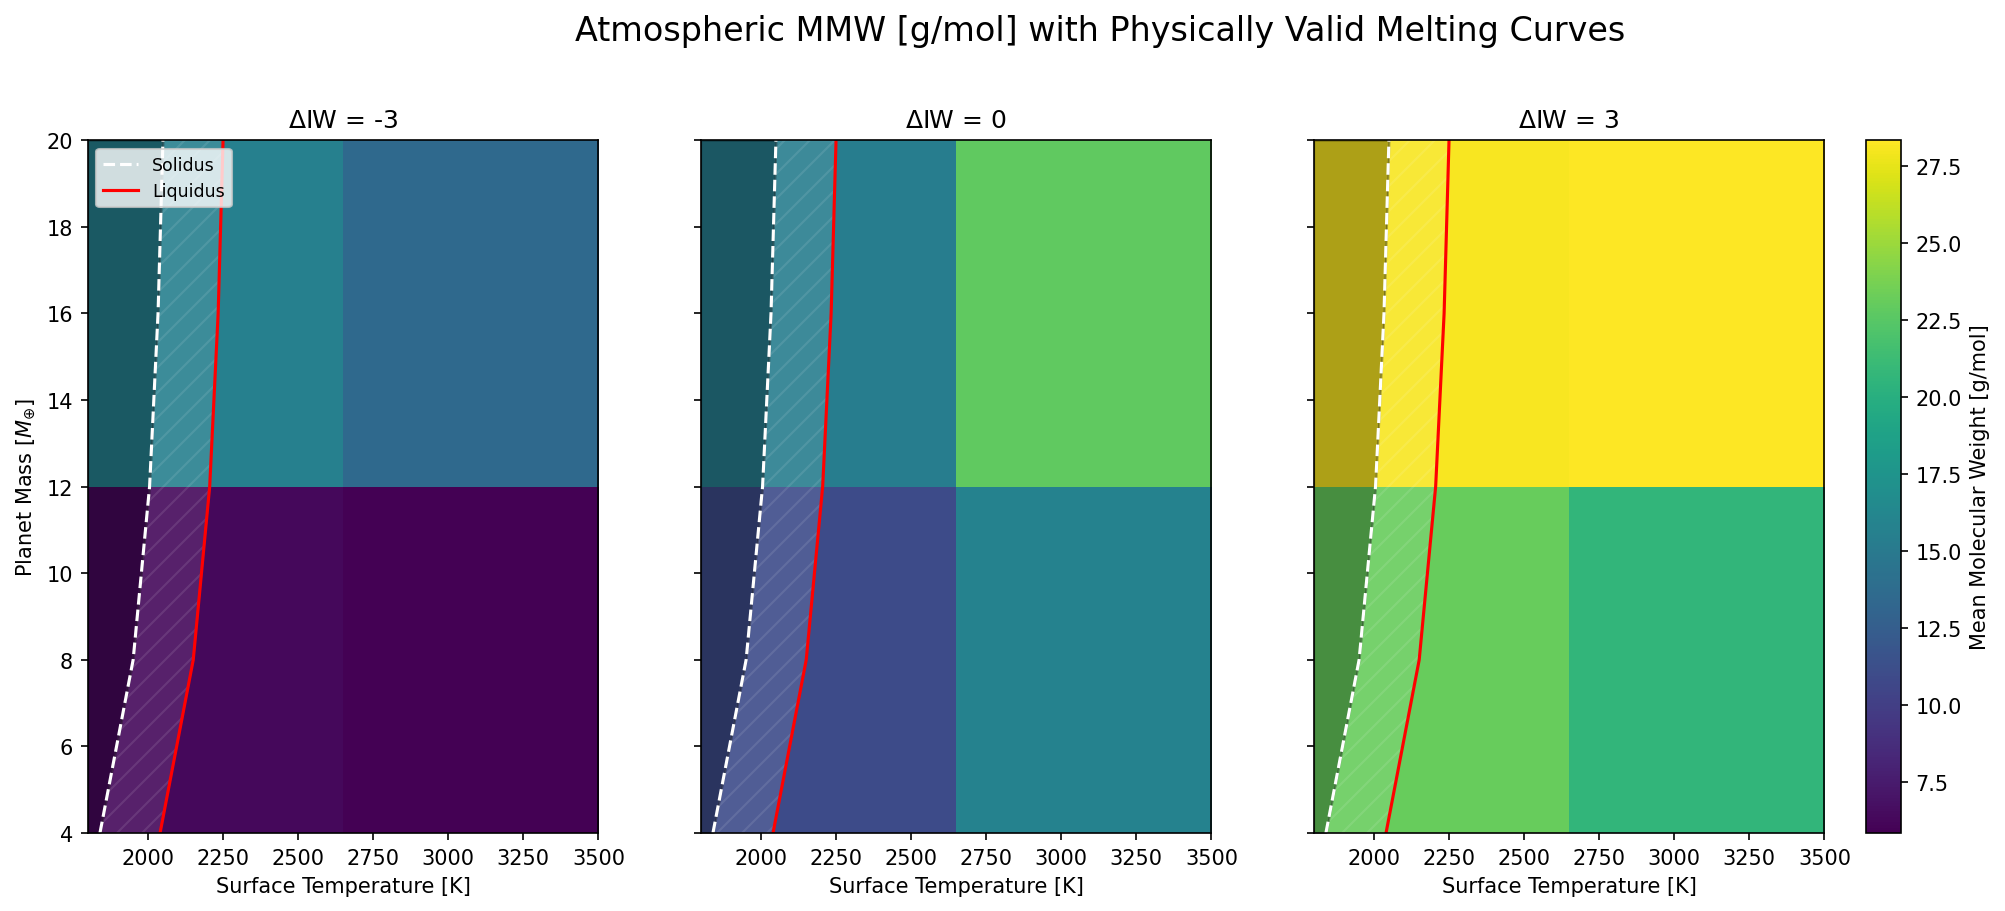

In [8]:
import logging
import numpy as np
import pandas as pd
import optimistix as optx
import matplotlib.pyplot as plt

# atmodeller imports
from atmodeller import (
    InteriorAtmosphere,
    Planet,
    SolverParameters,
    debug_logger,
)
from atmodeller.thermodata import IronWustiteBuffer
# from atmodeller import SpeciesCollection, species_real

logger = debug_logger()
logger.setLevel(logging.INFO)

M_EARTH = 5.972e24
R_EARTH = 6.371e6
G = 6.674e-11

MOLAR_MASSES = {
    'H2_g': 2.016, 'H2O_g': 18.015, 'CO_g': 28.010, 'CO2_g': 44.009,
    'CH4_g': 16.043, 'N2_g': 28.014, 'O2_g': 31.998, 'H3N_g': 17.031, 'He_g': 4.003,
}

solver = optx.LevenbergMarquardt
solver_parameters = SolverParameters(solver=solver)

def calculate_mmw(df_dict):
    mmw = 0.0
    found_any = False
    total_moles = 0.0
    for key, df in df_dict.items():
        if "atmosphere_moles" in df.columns:
            total_moles += df["atmosphere_moles"].iloc[-1]

    for species_name, molar_mass in MOLAR_MASSES.items():
        if species_name in df_dict:
            df = df_dict[species_name]
            if "volume_mixing_ratio" in df.columns:
                vmr = df["volume_mixing_ratio"].iloc[-1]
                mmw += (vmr * molar_mass)
                found_any = True
            elif "atmosphere_moles" in df.columns and total_moles > 0:
                moles = df["atmosphere_moles"].iloc[-1]
                vmr = moles / total_moles
                mmw += (vmr * molar_mass)
                found_any = True

    return mmw if found_any and mmw > 0 else np.nan

def compute_melting_temps(output):
    atm_df = output['atmosphere']
    P_surface_pa = atm_df['pressure'].iloc[-1]
    P_surface_GPa = P_surface_pa * 1e-4
    T_solidus_C = -5.104 * (P_surface_GPa**2) + 132.899 * P_surface_GPa + 1120.661
    T_solidus_K = T_solidus_C + 273.15
    T_liquidus_K = T_solidus_K + 200.0
    return T_solidus_K, T_liquidus_K

def estimate_mantle_melt_fraction(T_surf, output):
    T_sol, T_liq = compute_melting_temps(output)
    if T_surf < T_sol:
        return 0.01
    elif T_surf > T_liq:
        return 1.0
    else:
        return (T_surf - T_sol) / (T_liq - T_sol)

def solve_with_melt(T_surf, M_val, dIW_val, melt_guess):
    M_planet_kg = M_val * M_EARTH
    R_planet_m = 1.02 * (M_val)**(0.252) * R_EARTH
    H_mass = 0.01 * M_planet_kg
    mass_constraints = get_enriched_budget(H_mass)
    fO2 = {"O2_g": IronWustiteBuffer(dIW_val)}
    print(melt_guess)
    planet = Planet(
        surface_temperature=T_surf,
        planet_mass=M_planet_kg,
        surface_radius=R_planet_m,
        mantle_melt_fraction=melt_guess
    )
    model = InteriorAtmosphere(species_real)
    model.solve(
        planet=planet,
        mass_constraints=mass_constraints,
        fugacity_constraints=fO2,
        solver_parameters=solver_parameters,
    )
    return model.output.to_dataframes()

def solve_point_forward(T_list, M_val, dIW_val):
    mmw_values = []
    melt_guess = 1.0
    for T_surf in T_list:
        try:
            output = solve_with_melt(T_surf, M_val, dIW_val, melt_guess)
            melt_guess = estimate_mantle_melt_fraction(T_surf, output)
            mmw = calculate_mmw(output)
            mmw_values.append(mmw)
            if melt_guess == 0.0:
                melt_guess = 0.0
        except Exception as e:
            print(f"Failed at T={T_surf}, M={M_val}, dIW={dIW_val}: {e}")
            mmw_values.append(np.nan)
    return mmw_values

def get_melting_curves_for_masses(masses, T_hot):
    solidus = []
    liquidus = []
    for M_val in masses:
        try:
            output = solve_with_melt(T_hot, M_val, dIW_val=0, melt_guess=1.0)
            Tsol, Tliq = compute_melting_temps(output)
            solidus.append(Tsol)
            liquidus.append(Tliq)
        except Exception as e:
            print(f"Failed to get melt curve at M={M_val}: {e}")
            solidus.append(np.nan)
            liquidus.append(np.nan)
    return np.array(solidus), np.array(liquidus)

# --------------------------------------------------------------------
# 4. LOOP & PLOT
# --------------------------------------------------------------------
print("Starting simulation loop...")
dIW_scenarios = [-3, 0, 3]
Ts = np.linspace(1800, 3500, 2)
Ms_earth_units = np.linspace(4, 20, 2)
results = {}

for dIW in dIW_scenarios:
    print(f"--- Processing dIW = {dIW} ---")
    grid_data = np.zeros((len(Ms_earth_units), len(Ts)))
    for i, M_val in enumerate(Ms_earth_units):
        mmw_row = solve_point_forward(Ts[::-1], M_val, dIW)
        grid_data[i, :] = mmw_row[::-1]
    results[dIW] = grid_data

fig, axs = plt.subplots(1, 3, figsize=(18, 6), dpi=150, sharey=True)
fig.suptitle("Atmospheric MMW [g/mol] with Physically Valid Melting Curves", fontsize=16, y=1.02)

extent = [Ts.min(), Ts.max(), Ms_earth_units.min(), Ms_earth_units.max()]
all_vals = np.array([results[k] for k in results]).flatten()

vmin, vmax = (0, 1) if np.isnan(all_vals).all() else (np.nanmin(all_vals), np.nanmax(all_vals))

solidus_curve, liquidus_curve = get_melting_curves_for_masses(np.linspace(Ms_earth_units.min(), Ms_earth_units.max(), 5), T_hot=3500.0)

for i, dIW in enumerate(dIW_scenarios):
    ax = axs[i]
    data = results[dIW]
    im = ax.imshow(data, origin="lower", aspect="auto", extent=extent, cmap="viridis", vmin=vmin, vmax=vmax)
    ax.plot(solidus_curve, np.linspace(Ms_earth_units.min(), Ms_earth_units.max(), 5), '--', color='white', label='Solidus')
    ax.plot(liquidus_curve, np.linspace(Ms_earth_units.min(), Ms_earth_units.max(), 5), '-', color='red', label='Liquidus')
    ax.fill_betweenx(np.linspace(Ms_earth_units.min(), Ms_earth_units.max(), 5), solidus_curve, liquidus_curve, color='white', alpha=0.1, hatch='//')
    ax.fill_betweenx(np.linspace(Ms_earth_units.min(), Ms_earth_units.max(), 5), Ts.min(), solidus_curve, color='black', alpha=0.3)
    ax.set_title(f"$\\Delta$IW = {dIW}")
    ax.set_xlabel("Surface Temperature [K]")
    if i == 0:
        ax.set_ylabel("Planet Mass [$M_{\\oplus}$]")
        ax.legend(loc='upper left', fontsize='small')
    ax.set_xlim(1800, 3500)

if not np.isnan(all_vals).all():
    cbar = fig.colorbar(im, ax=axs.ravel().tolist(), pad=0.02)
    cbar.set_label("Mean Molecular Weight [g/mol]")

plt.show()

Starting simulation loop...
--- Processing dIW = -3 ---
--- Processing dIW = 0 ---
--- Processing dIW = 3 ---


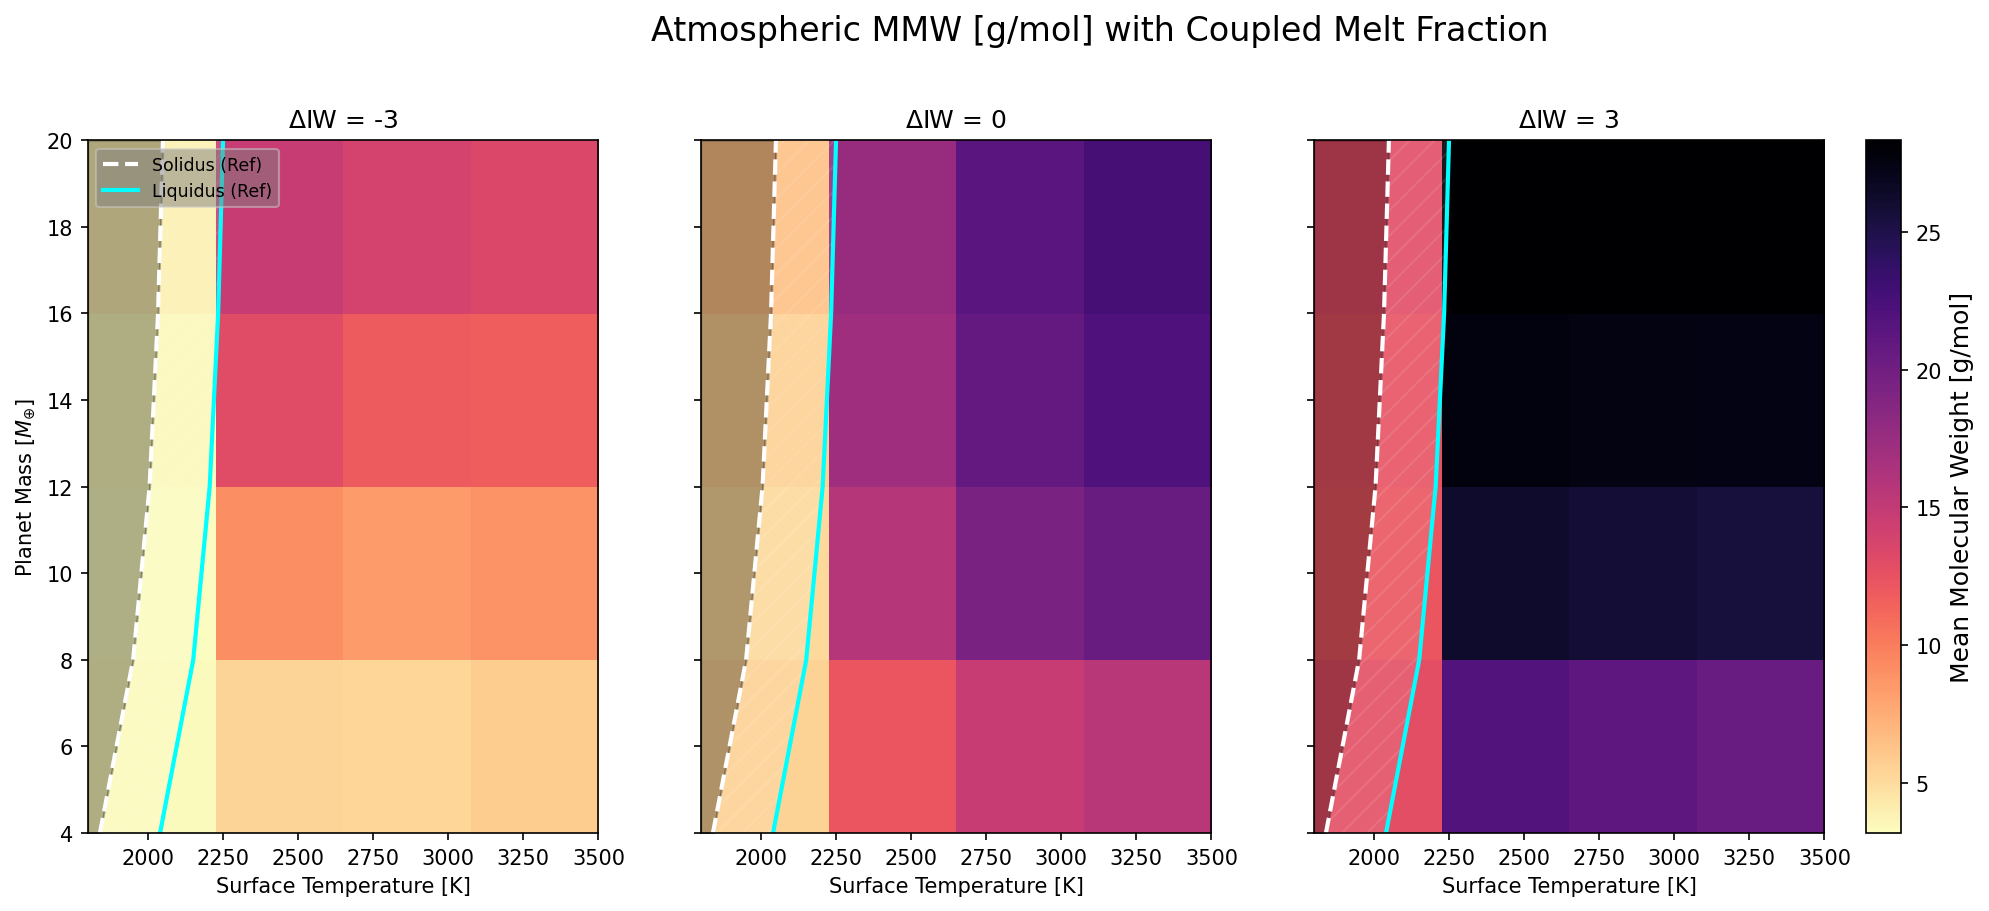

In [10]:
import logging
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import optimistix as optx
from typing import Tuple, Dict, Optional, List

# --------------------------------------------------------------------
# 1. IMPORTS & CONFIGURATION
# --------------------------------------------------------------------
# Try/Except block to handle the custom environment
try:
    from atmodeller import (
        InteriorAtmosphere,
        Planet,
        SolverParameters,
        debug_logger,
        SpeciesCollection, # Assuming this exists based on usage
        species_real       # Assuming this exists based on usage
    )
    from atmodeller.thermodata import IronWustiteBuffer
except ImportError:
    # Placeholder for the user if library isn't installed in this specific env
    print("Warning: 'atmodeller' not found. Ensure it is installed in your environment.")

# Configure Logging
logger = debug_logger()
logger.setLevel(logging.ERROR) # set to ERROR to reduce loop noise, INFO for debugging

# Constants
M_EARTH = 5.972e24
R_EARTH = 6.371e6
G = 6.674e-11

# Molar Masses (kg/mol or g/mol depending on consistency, assuming g/mol here)
MOLAR_MASSES = {
    'H2_g': 2.016, 'H2O_g': 18.015, 'CO_g': 28.010, 'CO2_g': 44.009,
    'CH4_g': 16.043, 'N2_g': 28.014, 'O2_g': 31.998, 'H3N_g': 17.031, 'He_g': 4.003,
}

# Solver Setup
solver = optx.LevenbergMarquardt
solver_parameters = SolverParameters(solver=solver)


# --------------------------------------------------------------------
# 2. HELPER FUNCTIONS
# --------------------------------------------------------------------


def calculate_mmw(df_dict: Dict[str, pd.DataFrame]) -> float:
    """Calculates Mean Molecular Weight from output dataframes."""
    mmw = 0.0
    found_any = False
    total_moles = 0.0
    
    # Calculate total moles first
    for df in df_dict.values():
        if "atmosphere_moles" in df.columns:
            total_moles += df["atmosphere_moles"].iloc[-1]

    if total_moles <= 0:
        return np.nan

    for species_name, molar_mass in MOLAR_MASSES.items():
        if species_name in df_dict:
            df = df_dict[species_name]
            vmr = 0.0
            
            if "volume_mixing_ratio" in df.columns:
                vmr = df["volume_mixing_ratio"].iloc[-1]
            elif "atmosphere_moles" in df.columns:
                moles = df["atmosphere_moles"].iloc[-1]
                vmr = moles / total_moles
            
            if vmr > 0:
                mmw += (vmr * molar_mass)
                found_any = True

    return mmw if found_any else np.nan

def compute_melting_temps(output: Dict[str, pd.DataFrame]) -> Tuple[float, float]:
    """Computes Solidus and Liquidus based on Surface Pressure."""
    atm_df = output['atmosphere']
    P_surface_pa = atm_df['pressure'].iloc[-1]
    P_surface_GPa = P_surface_pa * 1e-4 # Fixed conversion: 1e-9 for Pa to GPa
    
    # Solidus parameterization
    T_solidus_C = -5.104 * (P_surface_GPa**2) + 132.899 * P_surface_GPa + 1120.661
    T_solidus_K = T_solidus_C + 273.15
    T_liquidus_K = T_solidus_K + 200.0 # Simple offset assumption
    
    return T_solidus_K, T_liquidus_K

def calculate_required_melt_fraction(T_surf: float, output: Dict[str, pd.DataFrame]) -> float:
    """Determines what the melt fraction SHOULD be for a given output state."""
    T_sol, T_liq = compute_melting_temps(output)
    
    if T_surf < T_sol:
        return 0.01 # Minimum floor
    elif T_surf > T_liq:
        return 1.0 # Maximum cap
    else:
        return (T_surf - T_sol) / (T_liq - T_sol)

# --------------------------------------------------------------------
# 3. SOLVER LOGIC
# --------------------------------------------------------------------

def run_single_model(T_surf: float, M_val: float, dIW_val: float, melt_fraction: float) -> Dict[str, pd.DataFrame]:
    """Runs one instance of the solver with fixed parameters."""
    M_planet_kg = M_val * M_EARTH
    R_planet_m = 1.02 * (M_val)**(0.252) * R_EARTH
    H_mass = 0.01 * M_planet_kg
    
    mass_constraints = get_enriched_budget(H_mass)
    fO2 = {"O2_g": IronWustiteBuffer(dIW_val)}
    planet = Planet(
        surface_temperature=T_surf,
        planet_mass=M_planet_kg,
        surface_radius=R_planet_m,
        mantle_melt_fraction=melt_fraction
    )
    
    model = InteriorAtmosphere(species_real)
    model.solve(
        planet=planet,
        mass_constraints=mass_constraints,
        fugacity_constraints=fO2,
        solver_parameters=solver_parameters,
    )
    return model.output.to_dataframes()

def solve_equilibrium_state(T_surf: float, M_val: float, dIW_val: float, initial_guess: float = 0.5) -> Tuple[float, float]:
    """
    Iterates until the input melt fraction matches the output physical requirement.
    Returns (MMW, Final_Melt_Fraction).
    """
    current_melt = initial_guess
    tolerance = 0.05 # 5% tolerance
    max_iter = 5
    
    output = None
    
    for i in range(max_iter):
        try:
            # 1. Run Solver
            output = run_single_model(T_surf, M_val, dIW_val, current_melt)
            
            # 2. Check what the melt fraction SHOULD be based on the new P_surf
            required_melt = calculate_required_melt_fraction(T_surf, output)
            
            # 3. Check Convergence
            diff = abs(required_melt - current_melt)
            if diff < tolerance:
                # Converged
                break
            
            # 4. Update for next step (with slight relaxation to prevent oscillation)
            current_melt = 0.5 * current_melt + 0.5 * required_melt
            
        except Exception as e:
            # If solver fails, log and return NaNs
            # print(f"Solver Error at T={T_surf:.0f}, M={M_val}: {e}")
            return np.nan, current_melt

    if output is None:
        return np.nan, current_melt
        
    mmw = calculate_mmw(output)
    return mmw, current_melt

def solve_temperature_series(T_list: np.ndarray, M_val: float, dIW_val: float) -> np.ndarray:
    """Loops through a temperature list, using previous result as next guess."""
    mmw_values = []
    # Start assuming fully molten for high T, or start low for low T
    last_melt_fraction = 1.0 if T_list[0] > 2500 else 0.01 
    
    for T_surf in T_list:
        mmw, final_melt = solve_equilibrium_state(T_surf, M_val, dIW_val, initial_guess=last_melt_fraction)
        mmw_values.append(mmw)
        
        # Use valid result as guess for next T step for speed
        if not np.isnan(final_melt):
            last_melt_fraction = final_melt
            
    return np.array(mmw_values)

def get_melting_curves_reference(masses: np.ndarray, T_hot: float = 3500.0) -> Tuple[np.ndarray, np.ndarray]:
    """Calculates reference solidus/liquidus for plotting."""
    solidus = []
    liquidus = []
    for M_val in masses:
        try:
            # Run a dummy high-temp model just to get P_surf
            output = run_single_model(T_hot, M_val, dIW_val=0, melt_fraction=1.0)
            Tsol, Tliq = compute_melting_temps(output)
            solidus.append(Tsol)
            liquidus.append(Tliq)
        except Exception:
            solidus.append(np.nan)
            liquidus.append(np.nan)
    return np.array(solidus), np.array(liquidus)

# --------------------------------------------------------------------
# 4. MAIN EXECUTION & PLOTTING
# --------------------------------------------------------------------

if __name__ == "__main__":
    print("Starting simulation loop...")
    
    # Grid Setup
    dIW_scenarios = [-3, 0, 3]
    # Resolution increased slightly for better plotting
    Ts = np.linspace(1800, 3500, 4) 
    Ms_earth_units = np.linspace(4, 20, 4) 
    
    results = {}

    # Main Loop
    for dIW in dIW_scenarios:
        print(f"--- Processing dIW = {dIW} ---")
        grid_data = np.zeros((len(Ms_earth_units), len(Ts)))
        
        for i, M_val in enumerate(Ms_earth_units):
            # Pass Ts directly (no need to reverse unless specific physics require cooling path)
            mmw_row = solve_temperature_series(Ts, M_val, dIW)
            grid_data[i, :] = mmw_row
            
        results[dIW] = grid_data

    # Visualization
    fig, axs = plt.subplots(1, 3, figsize=(18, 6), dpi=150, sharey=True)
    fig.suptitle("Atmospheric MMW [g/mol] with Coupled Melt Fraction", fontsize=16, y=1.02)

    # Calculate global min/max for colorbar consistency
    all_vals = np.concatenate([v.flatten() for v in results.values()])
    vmin, vmax = (np.nanmin(all_vals), np.nanmax(all_vals)) if not np.isnan(all_vals).all() else (0, 1)

    # Calculate reference melting curves for plotting
    ref_masses = np.linspace(Ms_earth_units.min(), Ms_earth_units.max(), 5)
    solidus_curve, liquidus_curve = get_melting_curves_reference(ref_masses, T_hot=3500.0)

    for i, dIW in enumerate(dIW_scenarios):
        ax = axs[i]
        data = results[dIW]
        
        # Extent format: [xmin, xmax, ymin, ymax]
        extent = [Ts.min(), Ts.max(), Ms_earth_units.min(), Ms_earth_units.max()]
        
        im = ax.imshow(
            data, 
            origin="lower", 
            aspect="auto", 
            extent=extent, 
            cmap="magma_r", # 'magma_r' is often better for temperature/heat maps
            vmin=vmin, 
            vmax=vmax
        )
        
        # Plot Melting Curves
        ax.plot(solidus_curve, ref_masses, '--', color='white', linewidth=2, label='Solidus (Ref)')
        ax.plot(liquidus_curve, ref_masses, '-', color='cyan', linewidth=2, label='Liquidus (Ref)')
        
        # Shading regions
        ax.fill_betweenx(ref_masses, solidus_curve, liquidus_curve, color='white', alpha=0.1, hatch='//')
        ax.fill_betweenx(ref_masses, Ts.min(), solidus_curve, color='black', alpha=0.3)
        
        ax.set_title(f"$\\Delta$IW = {dIW}")
        ax.set_xlabel("Surface Temperature [K]")
        if i == 0:
            ax.set_ylabel("Planet Mass [$M_{\\oplus}$]")
            ax.legend(loc='upper left', fontsize='small', frameon=True, facecolor='grey', framealpha=0.5)
        
        ax.set_xlim(Ts.min(), Ts.max())
        ax.set_ylim(Ms_earth_units.min(), Ms_earth_units.max())

    # Colorbar
    if not np.isnan(all_vals).all():
        cbar = fig.colorbar(im, ax=axs.ravel().tolist(), pad=0.02)
        cbar.set_label("Mean Molecular Weight [g/mol]", fontsize=12)

    plt.show()

In [ ]:
import logging
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import optimistix as optx
from typing import Tuple, Dict

logger = debug_logger()
logger.setLevel(logging.INFO)

# Constants
M_EARTH = 5.972e24
R_EARTH = 6.371e6
MOLAR_MASS = {
    "H2_g": 2.016, "H2O_g": 18.015, "CO_g": 28.010,
    "CO2_g": 44.009, "CH4_g": 16.043, "N2_g": 28.014,
    "O2_g": 31.998, "H3N_g": 17.031, "He_g": 4.003
}

solver_parameters = SolverParameters(solver=optx.LevenbergMarquardt)

# ------------------------------------------------------------
# 2. PHYSICS
# ------------------------------------------------------------
def solidus_liquidus(P_pa: float) -> Tuple[float, float]:
    """Return solidus and liquidus temperatures (K) at pressure."""
    P = P_pa * 1e-4 # Pa → GPa
    Tsol_C = -5.104*P**2 + 132.899*P + 1120.661
    Tsol = Tsol_C + 273.15
    Tliq = Tsol + 200
    return Tsol, Tliq

def theoretical_melt_fraction(T: float, P: float) -> float:
    Tsol, Tliq = solidus_liquidus(P)
    if T < Tsol: return 0.01
    if T > Tliq: return 1.0
    return (T - Tsol) / (Tliq - Tsol)

# ------------------------------------------------------------
# 3. HELPERS
# ------------------------------------------------------------

def compute_mmw(dfs: Dict[str, pd.DataFrame]) -> float:
    """Compute mean molecular weight from species mole counts."""
    total = sum(df["atmosphere_moles"].iloc[-1]
                for df in dfs.values()
                if "atmosphere_moles" in df.columns)

    if total <= 0:
        return np.nan

    mmw = 0
    for sp, M in MOLAR_MASS.items():
        if sp in dfs and "atmosphere_moles" in dfs[sp]:
            moles = dfs[sp]["atmosphere_moles"].iloc[-1]
            mmw += M * (moles / total)

    return mmw

# ------------------------------------------------------------
# 4. CORE SOLVER LOOP
# ------------------------------------------------------------
def run_model(T, M_earth, dIW, melt_guess):
    """Run atmodeller and return dataframe results."""
    M = M_earth * M_EARTH
    R = 1.02 * M_earth**0.252 * R_EARTH
    H_mass = 1e-3 * M

    planet = Planet(
        surface_temperature=T,
        planet_mass=M,
        surface_radius=R,
        mantle_melt_fraction=melt_guess
    )

    model = InteriorAtmosphere(species_real)
    model.solve(
        planet=planet,
        mass_constraints=get_enriched_budget(H_mass),
        fugacity_constraints={"O2_g": IronWustiteBuffer(dIW)},
        solver_parameters=solver_parameters
    )

    return model.output.to_dataframes()

def solve_consistent(T, M, dIW):
    """Iteratively enforce melt fraction = theoretical melt fraction."""
    melt = 0.5

    for _ in range(5):
        try:
            dfs = run_model(T, M, dIW, melt)
        except:
            continue

        P = dfs["atmosphere"]["pressure"].iloc[-1]
        melt_req = theoretical_melt_fraction(T, P)

        if abs(melt_req - melt) < 0.02:
            return compute_mmw(dfs), P, melt_req

        melt = 0.5*(melt + melt_req)

    return np.nan, np.nan, np.nan

# ------------------------------------------------------------
# 5. RESULTS CHECK
# ------------------------------------------------------------
def integrity_test(results, Ms, Ts):
    print("\n=== INTEGRITY CHECK ===")
    dIW = next(iter(results.keys()))
    _, p_grid, melt_grid = results[dIW]

    mid_M = len(Ms)//2
    mid_T = len(Ts)//2

    T = Ts[mid_T]
    P = p_grid[mid_M, mid_T]
    melt = melt_grid[mid_M, mid_T]

    if np.isnan(melt):
        print("Test skipped: NaN at test gridpoint.")
        return

    melt_calc = theoretical_melt_fraction(T, P)
    print(f"T={T:.1f} K, P={P:.2e} Pa")
    print("Solver melt:", melt)
    print("Physics melt:", melt_calc)
    print("PASS" if abs(melt - melt_calc) < 1e-3 else "FAIL")

# ------------------------------------------------------------
# 6. TABLE PRINTER
# ------------------------------------------------------------
def print_melt_tables(results, dIW_vals, Ms, Ts):
    for dIW in dIW_vals:
        melt = results[dIW][2]
        df = pd.DataFrame(
            melt,
            index=[f"{m:.1f} M_E" for m in Ms],
            columns=[f"{t:.0f} K" for t in Ts]
        )
        print(f"\n=== Melt Fractions: dIW = {dIW} ===")
        print(df.iloc[::-1])

# ------------------------------------------------------------
# 7. MAIN
# ------------------------------------------------------------
if __name__ == "__main__":
    dIW_vals = [-3, 0, 3]
    Ts = np.linspace(1800, 3500, 2)
    Ms = np.linspace(4, 20, 2)

    results = {}

    for dIW in dIW_vals:
        mmw_grid = np.zeros((len(Ms), len(Ts)))
        p_grid   = np.zeros_like(mmw_grid)
        melt_grid= np.zeros_like(mmw_grid)

        for i, M in enumerate(Ms):
            for j, T in enumerate(Ts):
                mmw, P, melt = solve_consistent(T, M, dIW)
                mmw_grid[i, j] = mmw
                p_grid[i, j]   = P
                melt_grid[i, j]= melt

        results[dIW] = (mmw_grid, p_grid, melt_grid)

    integrity_test(results, Ms, Ts)
    print_melt_tables(results, dIW_vals, Ms, Ts)

    # ---- Plot ----
    fig, axs = plt.subplots(1, 3, figsize=(18, 6), dpi=150, sharey=True)
    fig.suptitle("Atmosphere MMW with Consistent Melt Fractions", fontsize=16)

    for ax, dIW in zip(axs, dIW_vals):
        mmw, p_grid, _ = results[dIW]

        valid = mmw[~np.isnan(mmw)]
        vmin, vmax = (valid.min(), valid.max()) if len(valid) else (0, 1)

        ax.imshow(
            mmw, origin="lower", aspect="auto",
            extent=[Ts.min(), Ts.max(), Ms.min(), Ms.max()],
            cmap="viridis", vmin=vmin, vmax=vmax
        )

        # Draw solidus and liquidus lines
        sol, liq = [], []
        for row in p_grid:
            P = np.nanmedian(row) if not np.all(np.isnan(row)) else np.nan
            Tsol, Tliq = solidus_liquidus(P)
            sol.append(Tsol)
            liq.append(Tliq)

        ax.plot(sol, Ms, "w--", label="Solidus")
        ax.plot(liq, Ms, "r-", label="Liquidus")

        ax.set_title(f"ΔIW = {dIW}")
        ax.set_xlabel("Temperature (K)")
        ax.legend()

    axs[0].set_ylabel("Mass (Earth units)")
    fig.colorbar(ax.images[-1], ax=axs, label="MMW (g/mol)")
    plt.show()


[17:23:43 - atmodeller.classes             - INFO     ] - species = ('H2O_g: CombinedRealGas, SolubilityPowerLaw', 'H2_g: CombinedRealGas, SolubilityPowerLawLog10', 'O2_g: CombinedRealGas, NoSolubility', 'CO2_g: CombinedRealGas, _CO2_basalt_dixon95', 'CO_g: CombinedRealGas, _CO_basalt_yoshioka19', 'CH4_g: CombinedRealGas, _CH4_basalt_ardia13', 'N2_g: CombinedRealGas, _N2_basalt_libourel03', 'H3N_g: RedlichKwong49, NoSolubility', 'CHN_g: RedlichKwong49, NoSolubility', 'He_g: CombinedRealGas, SolubilityPowerLaw')
[17:23:43 - atmodeller.classes             - INFO     ] - Thermodynamic data requires temperatures between 200 K and 6000 K
[17:23:43 - atmodeller.classes             - INFO     ] - reactions = {0: '2.0 H2_g + 2.0 CO_g = 1.0 CO2_g + 1.0 CH4_g',
 1: '1.0 H2_g + 1.0 CO2_g = 1.0 H2O_g + 1.0 CO_g',
 2: '1.5 H2_g + 0.5 N2_g = 1.0 H3N_g',
 3: '0.5 H2_g + 2.0 CO_g + 0.5 N2_g = 1.0 CO2_g + 1.0 CHN_g',
 4: '2.0 CO2_g = 1.0 O2_g + 2.0 CO_g'}
[17:23:43 - atmodeller.classes             - IN

ERROR: 'atmodeller' not found. Exiting.


[17:23:44 - atmodeller.classes             - WARNING  ] - 1 model(s) failed to converge on the first attempt
[17:23:44 - atmodeller.classes             - WARNING  ] - But don't panic! This can happen when starting from a poor initial guess.
[17:23:44 - atmodeller.classes             - WARNING  ] - Launching multistart (maximum 10 attempts)
[17:23:44 - atmodeller.classes             - WARNING  ] - Attempting to solve the 1 models(s) that initially failed
[17:24:51 - atmodeller.classes             - INFO     ] - species = ('H2O_g: CombinedRealGas, SolubilityPowerLaw', 'H2_g: CombinedRealGas, SolubilityPowerLawLog10', 'O2_g: CombinedRealGas, NoSolubility', 'CO2_g: CombinedRealGas, _CO2_basalt_dixon95', 'CO_g: CombinedRealGas, _CO_basalt_yoshioka19', 'CH4_g: CombinedRealGas, _CH4_basalt_ardia13', 'N2_g: CombinedRealGas, _N2_basalt_libourel03', 'H3N_g: RedlichKwong49, NoSolubility', 'CHN_g: RedlichKwong49, NoSolubility', 'He_g: CombinedRealGas, SolubilityPowerLaw')
[17:24:51 - atmodeller.cl